# 0.0 Imports

In [ ]:
import gc
import builtins          as bt
import inflection
import lightgbm          as lgb
import math
import matplotlib.pyplot as plt
import numpy             as np
import pandas            as pd
import random
import seaborn           as sns
import shap

from boruta                    import BorutaPy
from collections               import Counter
from IPython.display           import Image as image
from scipy                     import stats as ss
from sklearn                   import ensemble as en
from sklearn                   import metrics as mt
from sklearn                   import preprocessing as pp
from sklearn.calibration       import calibration_curve
from sklearn.ensemble          import RandomForestClassifier
from sklearn.feature_selection import RFE, RFECV, VarianceThreshold
from sklearn.linear_model      import LogisticRegression
from sklearn.metrics           import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection   import cross_validate, train_test_split, RandomizedSearchCV, StratifiedKFold
from scipy                     import stats
from tabulate                  import tabulate
from typing                    import Dict, List
from xgboost                   import XGBClassifier

## 0.1 Helper Functions

In [198]:
# Função para colocar o ponto perto do próximo mínimo multiplo de bucket_size
def bucketize(point: float, bucket_size:float) -> float:
    return bucket_size * math.floor(point / bucket_size)

# Função para colocar os pontos em bukets e conta o número de pontos em cada bucket
def make_histogram(points: List[float], bucket_size: float) -> Dict[float, int]:
    return Counter([bucketize(point, bucket_size) for point in points])

def plot_histogram(points: List[float], bucket_size: float, title: str=""):
    histogram = make_histogram(points, bucket_size)
    plt.bar(histogram.keys(), histogram.values(), width=bucket_size)
    plt.title(title)

# Função métricas de avaliação de modelos
def ml_metrics(model_name, y_true, y_prob, threshold =0.5):
    y_pred = [ 1 if x > threshold else 0 for x in y_prob ]
    acc = mt.accuracy_score( y_true, y_pred )
    f1 = mt.f1_score( y_true, y_pred, zero_division=0 )
    prec = mt.precision_score( y_true, y_pred, zero_division=0 )
    rec = mt.recall_score(y_true, y_pred, zero_division=0)
    auc = mt.roc_auc_score(y_true, y_pred)
    roc_auc = mt.roc_auc_score(y_true, y_prob),

    return pd.DataFrame({
        'Model': model_name,
        'Accuracy': acc,
        'F1 Score': f1,
        'precision': prec,
        'Recall': rec,
        'AUC': auc,
        'ROC AUC': mt.roc_auc_score(y_true, y_prob),
    }, index=[0])

# Função para o boruta--- Reverter dummies para nome original
def to_original( col ):
    return col.split( '__SEP__' )[0] if '__SEP__' in col else col

## 0.2 Loading data

### 0.2.1 Data Train

In [199]:
df_raw = pd.read_csv('../dataset/train.csv')

In [200]:
df_raw.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [201]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   699635 non-null

### 0.2.2 Data Test

In [202]:
df_test = pd.read_csv('../dataset/test.csv')

# 1.0 DESCRICAO DOS DADOS

In [203]:
df1 = df_raw.copy()

In [204]:
df1.columns

Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class', 'satisfaction'],
      dtype='str')

## 1.1 Rename columns

In [205]:

cols_old = [['id', 'Age', 'Flight Distance', 'Inflight wifi service',
             'Departure/Arrival time convenient', 'Ease of Online booking',
             'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 
             'Inflight entertainment', 'On-board service', 'Leg room service', 
             'Baggage handling', 'Checkin service', 'Cleanliness',
             'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
             'Customer Type', 'Type of Travel', 'Class', 'satisfaction']]

snakecase = lambda x: inflection.underscore( x.replace(" ", "_").replace("/", "_") )
cols_new = list(map(snakecase, cols_old[0]))

#rename
df1.columns = cols_new

In [206]:
cols_new

['id',
 'age',
 'flight_distance',
 'inflight_wifi_service',
 'departure_arrival_time_convenient',
 'ease_of_online_booking',
 'gate_location',
 'food_and_drink',
 'online_boarding',
 'seat_comfort',
 'inflight_entertainment',
 'on_board_service',
 'leg_room_service',
 'baggage_handling',
 'checkin_service',
 'cleanliness',
 'departure_delay_in_minutes',
 'arrival_delay_in_minutes',
 'gender',
 'customer_type',
 'type_of_travel',
 'class',
 'satisfaction']

## 1.2 Data Dimensions

In [207]:
print('Number of rows: {}'.format(df1.shape[0]))
print('Number of columns: {}'.format(df1.shape[1]))

Number of rows: 699635
Number of columns: 23


## 1.3 Data Types


In [208]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   age                                699635 non-null  int64  
 2   flight_distance                    699635 non-null  int64  
 3   inflight_wifi_service              699635 non-null  int64  
 4   departure_arrival_time_convenient  699635 non-null  int64  
 5   ease_of_online_booking             699635 non-null  int64  
 6   gate_location                      699635 non-null  int64  
 7   food_and_drink                     699635 non-null  int64  
 8   online_boarding                    699635 non-null  int64  
 9   seat_comfort                       699635 non-null  int64  
 10  inflight_entertainment             699635 non-null  int64  
 11  on_board_service                   699635 non-null

In [209]:
df1['satisfaction'].unique()


array([False,  True])

In [210]:
#TRANSFORMANDO BOLEANO EM NÚMERO INTEIRO
df1['satisfaction'] = df1['satisfaction'].astype(int)

In [211]:
pd.set_option("display.max_columns", None)
df1.head()

,id,age,flight_distance,inflight_wifi_service,departure_arrival_time_convenient,ease_of_online_booking,gate_location,food_and_drink,online_boarding,seat_comfort,inflight_entertainment,on_board_service,leg_room_service,baggage_handling,checkin_service,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,gender,customer_type,type_of_travel,class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,0


In [212]:
df1.isna().sum()

id                                     0
age                                    0
flight_distance                        0
inflight_wifi_service                  0
departure_arrival_time_convenient      0
ease_of_online_booking                 0
gate_location                          0
food_and_drink                         0
online_boarding                        0
seat_comfort                           0
inflight_entertainment                 0
on_board_service                       0
leg_room_service                       0
baggage_handling                       0
checkin_service                        0
cleanliness                            0
departure_delay_in_minutes             0
arrival_delay_in_minutes             292
gender                                 0
customer_type                          0
type_of_travel                         0
class                                  0
satisfaction                           0
dtype: int64

## 1.5 Fillout NA

In [213]:
#logica de preenchimento de valores nulos, caso o valor de 'Arrival Delay in Minutes' seja nulo, ele será preenchido com o valor de 'Departure Delay in Minutes'
# os valores de Arrival Delay in Minutes e Departure Delay in Minutes são muito próximos e com alta correlação, 
# então preencher os valores nulos de Arrival Delay in Minutes com os valores de Departure Delay in Minutes pode ser uma boa estratégia para lidar com os valores nulos.
# outra estratégia boa seria apagar esses campos, mas perde dados. A média não é estratégia boa por conta do desbalanceamento dos dados, a mediana também não é boa por conta do desbalanceamento dos dados, e o valor mais frequente também não é boa estratégia por conta do desbalanceamento dos dados.
c = "arrival_delay_in_minutes"
d = "departure_delay_in_minutes"
df1[c] = df1[c].fillna(df1[d])


In [214]:
df1.isna().sum()

id                                   0
age                                  0
flight_distance                      0
inflight_wifi_service                0
departure_arrival_time_convenient    0
ease_of_online_booking               0
gate_location                        0
food_and_drink                       0
online_boarding                      0
seat_comfort                         0
inflight_entertainment               0
on_board_service                     0
leg_room_service                     0
baggage_handling                     0
checkin_service                      0
cleanliness                          0
departure_delay_in_minutes           0
arrival_delay_in_minutes             0
gender                               0
customer_type                        0
type_of_travel                       0
class                                0
satisfaction                         0
dtype: int64

## 1.7 Descriptive Statistical

In [215]:
num_attributes = df1.select_dtypes(include=['int64', 'float64']).drop(columns=['id'])
cat_attributes = df1.select_dtypes(exclude=['int64', 'float64'])

In [216]:
display(num_attributes)

,age,flight_distance,inflight_wifi_service,departure_arrival_time_convenient,ease_of_online_booking,gate_location,food_and_drink,online_boarding,seat_comfort,inflight_entertainment,on_board_service,leg_room_service,baggage_handling,checkin_service,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,satisfaction
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,1
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,0
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,0
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699630,57,612,2,1,1,1,1,3,3,2,2,2,2,2,4,0,0.0,0
699631,30,862,2,2,2,3,4,2,4,4,2,5,4,2,4,24,34.0,0
699632,49,3148,5,5,5,5,4,4,4,5,5,5,5,5,5,0,0.0,1
699633,61,679,5,2,2,2,5,4,4,5,4,5,5,5,1,0,0.0,1


In [217]:
# Satisfação: 1 = satisfeitos, 0 = não satisfeitos
satisfaction_counts = df1['satisfaction'].value_counts()
print(f'Quantidade de passageiros satisfeitos: {satisfaction_counts[1]}')
print(f'Quantidade de passageiros insatisfeitos: {satisfaction_counts[0]}')

# Proporção de passageiros satisfeitos e insatisfeitos
satisfaction_proportion = df1['satisfaction'].value_counts(normalize=True)*100
print(f'Proporção de passageiros satisfeitos: {satisfaction_proportion[1]:.2f}%')
print(f'Proporção de passageiros insatisfeitos: {satisfaction_proportion[0]:.2f}%')

Quantidade de passageiros satisfeitos: 310339
Quantidade de passageiros insatisfeitos: 389296
Proporção de passageiros satisfeitos: 44.36%
Proporção de passageiros insatisfeitos: 55.64%


In [218]:
display(cat_attributes)

,gender,customer_type,type_of_travel,class
0,Female,Loyal Customer,Personal Travel,Eco
1,Male,Loyal Customer,Business travel,Business
2,Female,Loyal Customer,Personal Travel,Eco
3,Male,Loyal Customer,Personal Travel,Eco
4,Female,disloyal Customer,Business travel,Eco
...,...,...,...,...
699630,Female,Loyal Customer,Business travel,Eco
699631,Female,disloyal Customer,Business travel,Eco
699632,Male,Loyal Customer,Business travel,Business
699633,Female,Loyal Customer,Business travel,Eco


## 1.7.1 Numerical Attributes

In [219]:
#numerical statistics
#Central Tendency - mean, median
ct1 = pd.DataFrame(num_attributes.apply(np.mean)).T #média
ct2 = pd.DataFrame(num_attributes.apply(np.median)).T #mediana


#Dispersion - std, min, max, range, skew, kurtosis
d1 = pd.DataFrame(num_attributes.apply(np.std)).T                      #desvio padrão
d2 = pd.DataFrame(num_attributes.apply(min)).T                         #min
d3 = pd.DataFrame(num_attributes.apply(max)).T                         #max
d4 = pd.DataFrame(num_attributes.apply(lambda x: x.max() - x.min())).T #range
d5 = pd.DataFrame(num_attributes.apply(lambda x: x.skew())).T          #skew
d6 = pd.DataFrame(num_attributes.apply(lambda x: x.kurtosis())).T      #kurtosis

#Concatenar os dataframes de central tendency e dispersion
m = pd.concat([d2, d3, d4, ct1, ct2, d1, d5, d6]).T.reset_index()
m.columns = ['attributes', 'min', 'max', 'range', 'mean', 'median', 'std', 'skew', 'kurtosis']

In [220]:
#dataframes de central tendency e dispersion
m

,attributes,min,max,range,mean,median,std,skew,kurtosis
0,age,7.0,85.0,78.0,39.001928,40.0,13.800933,-0.049710,-0.738916
1,flight_distance,67.0,4983.0,4916.0,1353.778702,954.0,954.421884,1.080466,0.132785
2,inflight_wifi_service,0.0,5.0,5.0,2.778722,3.0,1.280418,0.088131,-0.795488
3,departure_arrival_time_convenient,0.0,5.0,5.0,3.156210,3.0,1.475389,-0.380044,-0.970400
4,ease_of_online_booking,0.0,5.0,5.0,2.813240,3.0,1.329549,0.040290,-0.877128
5,gate_location,0.0,5.0,5.0,3.013734,3.0,1.254014,-0.103855,-0.932468
6,food_and_drink,0.0,5.0,5.0,3.265644,3.0,1.300201,-0.186879,-1.088510
7,online_boarding,0.0,5.0,5.0,3.364156,4.0,1.288537,-0.464915,-0.658722
8,seat_comfort,0.0,5.0,5.0,3.568950,4.0,1.275332,-0.616192,-0.682405
9,inflight_entertainment,0.0,5.0,5.0,3.453910,4.0,1.308156,-0.466777,-0.921351


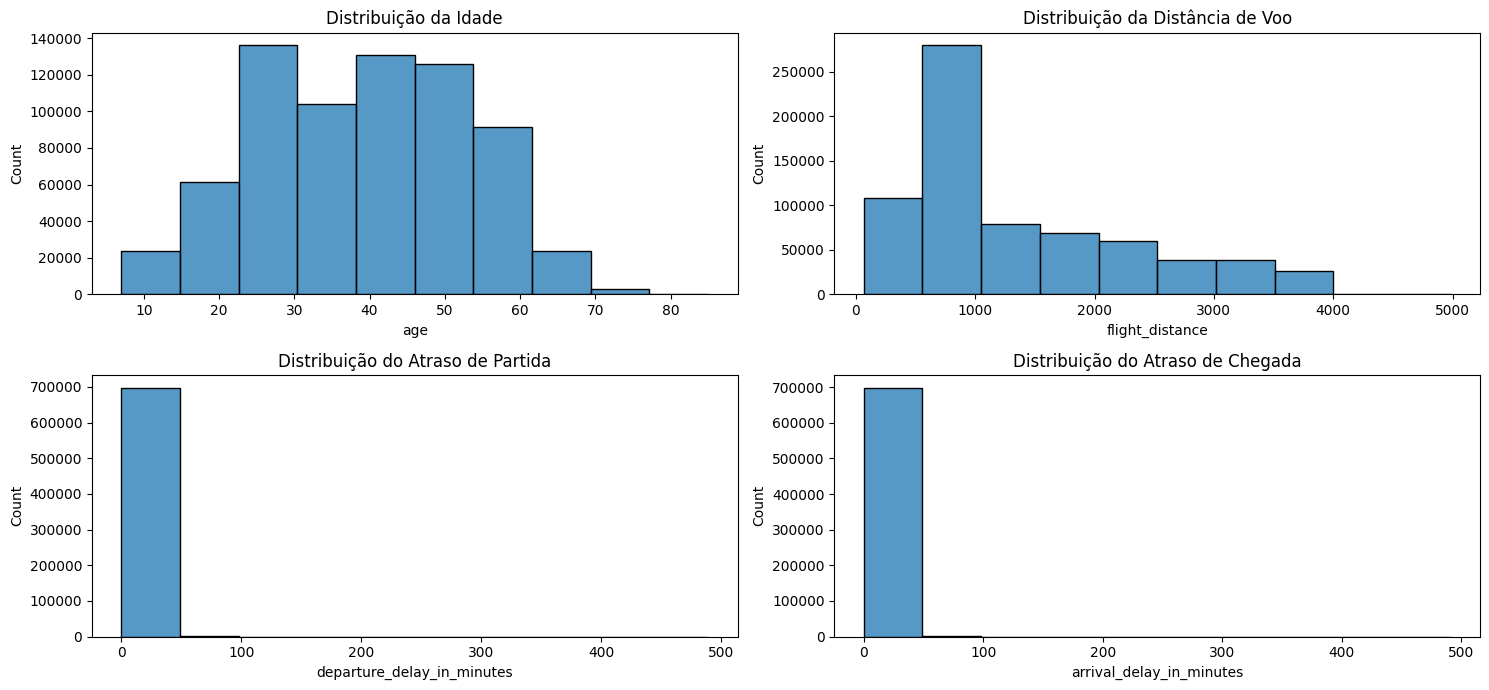

In [221]:
# Criar uma figura com 2 linhas e 2 colunas
fig, axes = plt.subplots(2, 2, figsize=(15, 7))

# Age
sns.histplot(df1['age'], bins=10, ax=axes[0, 0])
axes[0, 0].set_title('Distribuição da Idade')

# Distância de voo (flight distance)
sns.histplot(df1['flight_distance'], bins=10, ax=axes[0, 1])
axes[0, 1].set_title('Distribuição da Distância de Voo')

# Atraso de partida (departure delay)
sns.histplot(df1['departure_delay_in_minutes'], bins=10, ax=axes[1, 0])
axes[1, 0].set_title('Distribuição do Atraso de Partida')

# Atraso de chegada (arrival delay)
sns.histplot(df1['arrival_delay_in_minutes'], bins=10, ax=axes[1, 1])
axes[1, 1].set_title('Distribuição do Atraso de Chegada')

# Ajustar o espaçamento
plt.tight_layout()

# Exibir os gráficos
plt.show()

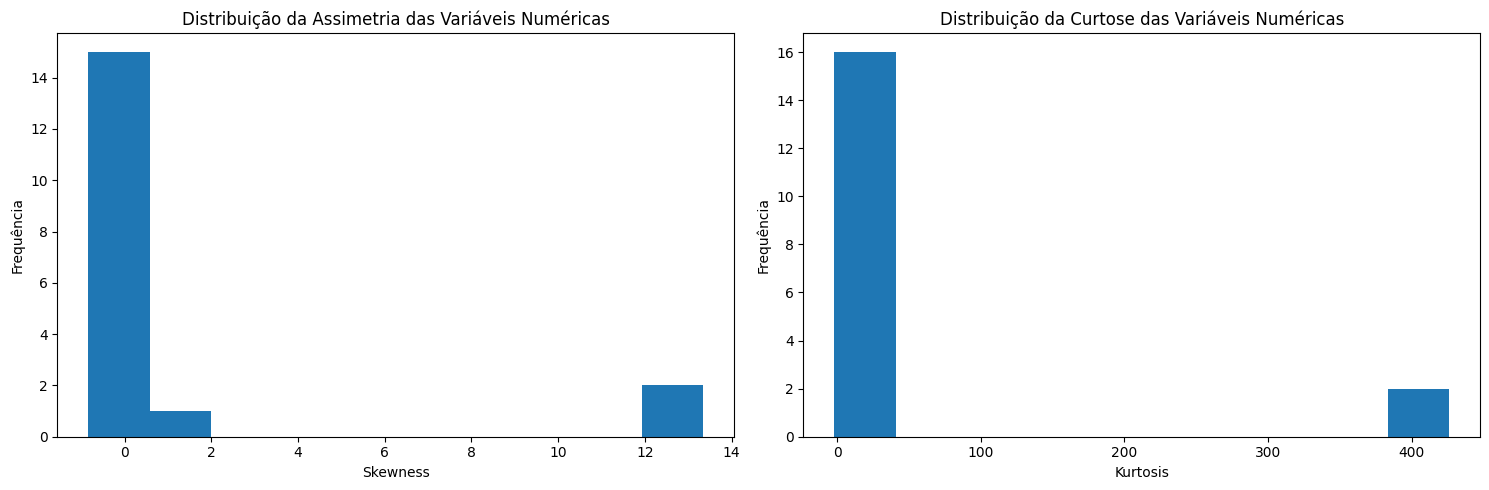

In [222]:
# Criar uma figura com 1 linha e 2 colunas
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histograma Skewness (Assimetria): negativo = cauda esquerda, positivo = cauda direita, 0 = simetria
axes[0].hist(d5.T.values.flatten(), bins=10)
axes[0].set_ylabel('Frequência')
axes[0].set_title('Distribuição da Assimetria das Variáveis Numéricas')
axes[0].set_xlabel('Skewness')

# Histograma Kurtosis (Curtose): relacionada ao comportamento das caudas e à ocorrência de valores extremos
axes[1].hist(d6.T.values.flatten(), bins=10)
axes[1].set_ylabel('Frequência')
axes[1].set_title('Distribuição da Curtose das Variáveis Numéricas')
axes[1].set_xlabel('Kurtosis')

# Ajustar o espaçamento
plt.tight_layout()

# Exibir os gráficos
plt.show()

## 1.7.2 Categorical Attributes

In [223]:
cat_attributes.apply(lambda x: x.unique().shape[0])

gender            2
customer_type     2
type_of_travel    2
class             3
dtype: int64

<Axes: xlabel='gender', ylabel='satisfaction'>

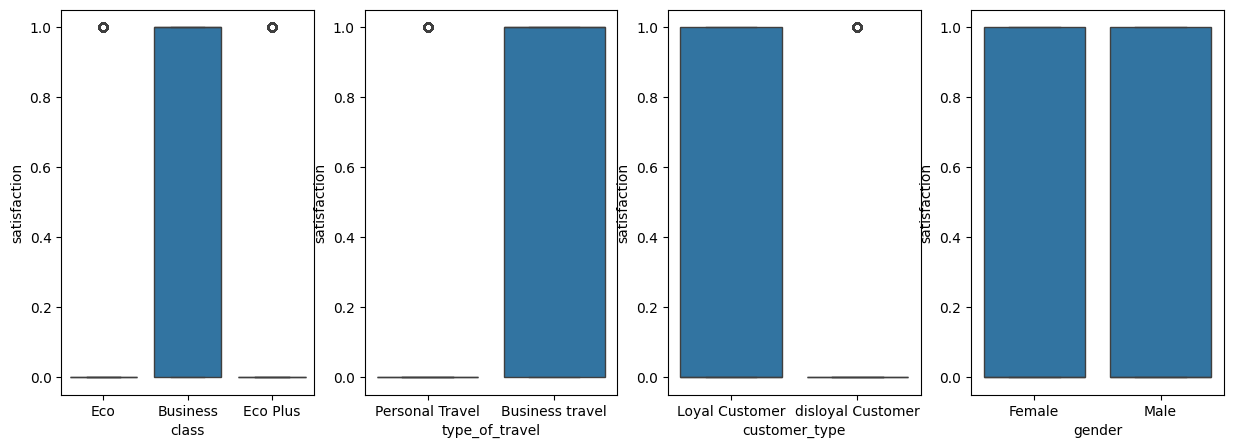

In [224]:
#boxplot
aux1 = pd.concat([cat_attributes, df1['satisfaction']], axis=1)

plt.figure(figsize=(15, 5))
plt.subplot(1, 4, 1)
sns.boxplot(x='class', y='satisfaction', data=aux1)

plt.subplot(1, 4, 2)
sns.boxplot(x='type_of_travel', y='satisfaction', data=aux1)

plt.subplot(1, 4, 3)
sns.boxplot(x='customer_type', y='satisfaction', data=aux1)

plt.subplot(1, 4, 4)
sns.boxplot(x='gender', y='satisfaction', data=aux1)

# 2.0 FEATURE ENGINEERING

## Mapa mental de hipóteses

- Fenômeno: Satisfação do cliente (variável dependente ou resposta = y).
- Agentes: Variáveis que impactam o fenômeno (variáveis independentes = x)
- Atributos do agente: características dos atributos.

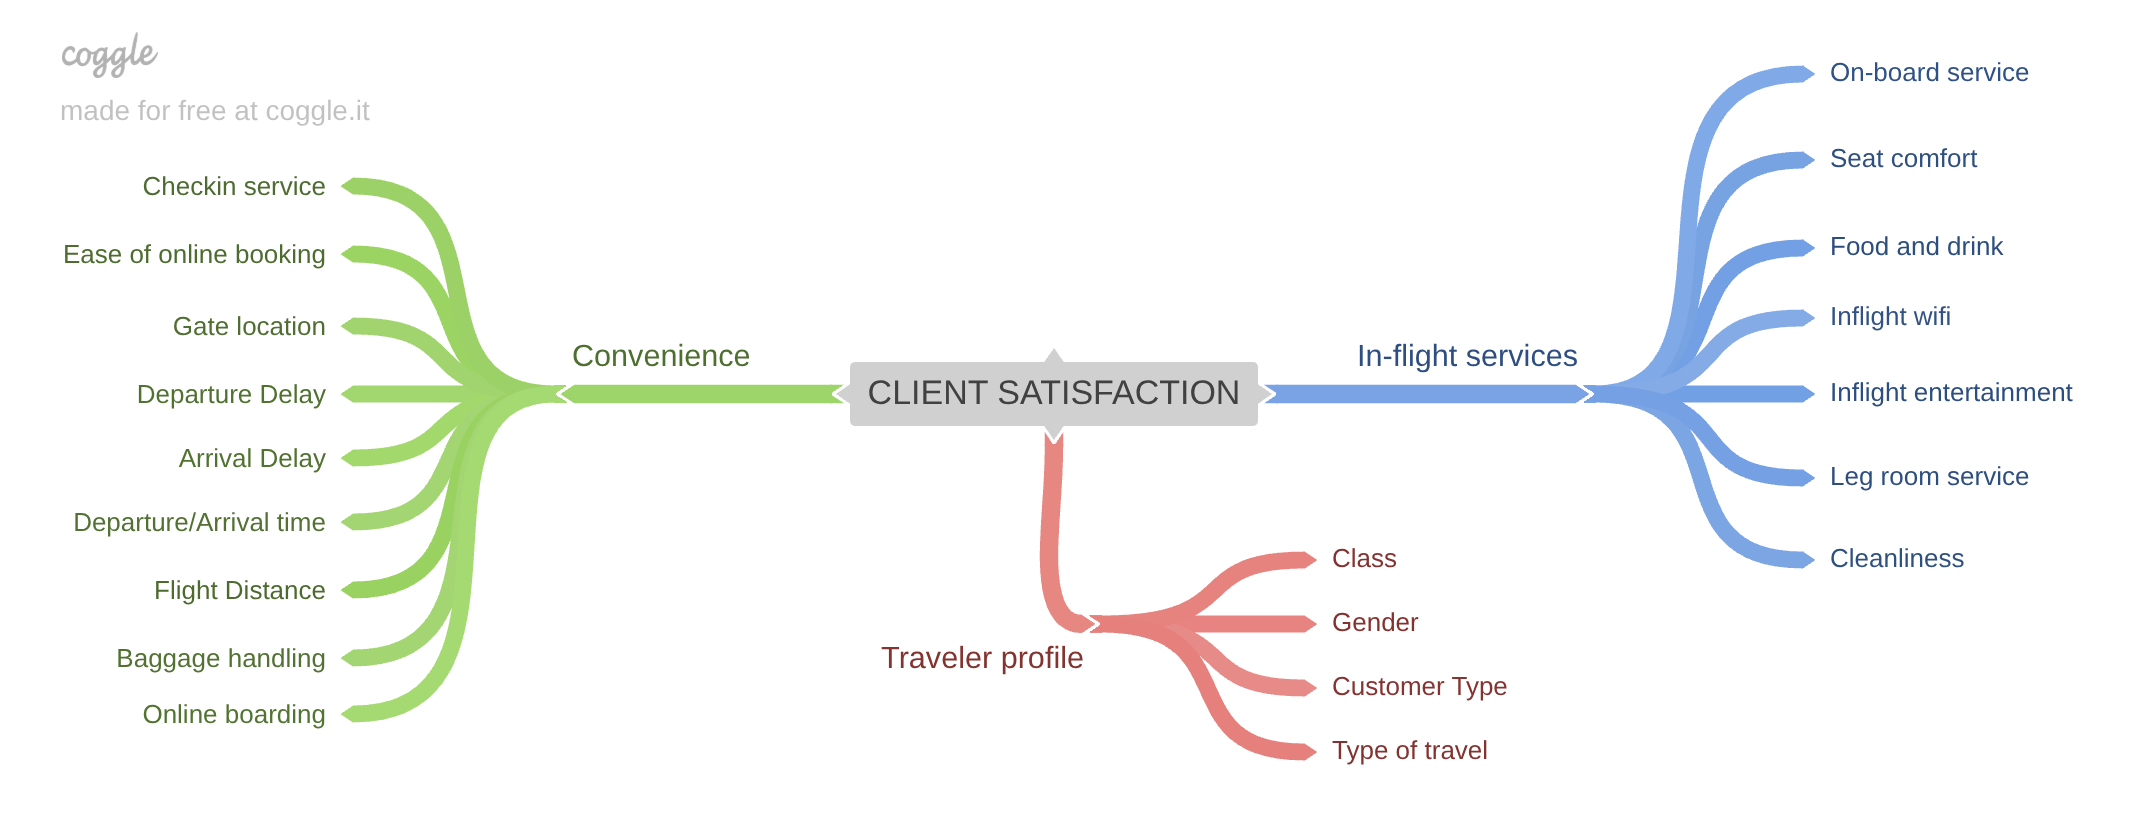

In [225]:
image('../img/client_satisfaction.png')

## 2.1 Criação das hipóteses

22 Hipóteses foram geradas considerando três frentes: conveniência, serviços a bordo e perfil do viajante.
Para vadiação ou refutação do teste de crenças.

### Hipóteses com dados disponíveis:
#### 2.1.1 Serviços de Conveniência

**1** Facilidade de autoserviço online de agendamento aumenta o nível de satisfação do cliente.

**2** Facilidade de autoserviço online de check-in aumenta o nível de satisfação do cliente.

**3** Facilidade de autoserviço online cartão de embarque aumenta o nível de satisfação do cliente.

**4** O atraso na saída ou na chegada do vôo diminuem a satisfação do cliente.

**5** A disponibilidade de vôos em horário conveniente de partida e chegada aumentam a satisfação do cliente.

**6** Distâncias maiores de vôo diminuem a satisfação do cliente.

**7** A localização do portão aumenta a satisfação do cliente.

**8** O serviço de manuseio de bagagem aumenta a satisfação do cliente.

#### 2.1.2 Serviços durante o vôo

**1** Quanto maior a satisfação com o serviço a bordo maior a satisfação do cliente.

**2** Quanto maior a satisfação com o conforto do assento maior a satisfação do cliente.

**3** Quanto maior a satisfação com o serviço de comida e bebida a bordo maior a satisfação do cliente.

**4** Quanto maior a satisfação com o serviço de wifi a bordo maior a satisfação do cliente.

**5** Quanto maior a satisfação com o serviço de entretenimento a bordo maior a satisfação do cliente.

**6** Quanto maior a satisfação com o serviço de espaço para as pernas maior a satisfação do cliente.

**7** Quanto maior a satisfação com o serviço de limpeza a bordo maior a satisfação do cliente.

#### 2.1.3 Perfil do Viajante

**1** Quanto maior a idade menor o nível de satisfação do cliente.

**2** O gênero feminino sente maior de satisfação em relação aos serviços abordo.

**3** A classe de viajante Business tem maior nível de satisfação.

**4** A classe de viajante Eco Plus tem maior nível de satisfação.

**5** A classe de viajante Eco tem menor nível de satisfação.

**6** O cliente fidelizado tem maior nível de satisfação.

**7** Viajantes a trabalho tem maior nível de satisfação.

## 2.2 Lista final de hipóteses

**1** Facilidade de autoserviço online de agendamento aumenta o nível de satisfação do cliente.

**2** O atraso na saída ou na chegada do vôo diminuem a satisfação do cliente.

**3** Distâncias maiores de vôo diminuem a satisfação do cliente.

**4** Quanto maior a satisfação com o serviço a bordo maior a satisfação do cliente.

**5** Quanto maior a satisfação com o serviço de wifi a bordo maior a satisfação do cliente.

**6** Quanto maior a satisfação com o serviço de entretenimento a bordo maior a satisfação do cliente.

**7** Quanto maior a satisfação com o conforto do assento maior a satisfação do cliente.

**8** Quanto maior a satisfação com o serviço de limpeza a bordo maior a satisfação do cliente.

**9** A classe de viajante Eco tem menor nível de satisfação.

**10** O cliente fidelizado tem maior nível de satisfação.

**11** Viajantes a trabalho tem maior nível de satisfação.

### Feature Engineering

In [226]:
del (df_raw)

In [227]:
df2 = df1.copy()
df2.dtypes

id                                     int64
age                                    int64
flight_distance                        int64
inflight_wifi_service                  int64
departure_arrival_time_convenient      int64
ease_of_online_booking                 int64
gate_location                          int64
food_and_drink                         int64
online_boarding                        int64
seat_comfort                           int64
inflight_entertainment                 int64
on_board_service                       int64
leg_room_service                       int64
baggage_handling                       int64
checkin_service                        int64
cleanliness                            int64
departure_delay_in_minutes             int64
arrival_delay_in_minutes             float64
gender                                   str
customer_type                            str
type_of_travel                           str
class                                    str
satisfacti

# 3.0 ANÁLISE EXPLORATÓRIA DOS DADOS - EDA

## 3.1 Análise Exploratória Univariada

### 3.1.1 Numerical Variable

array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'flight_distance'}>,
        <Axes: title={'center': 'inflight_wifi_service'}>,
        <Axes: title={'center': 'departure_arrival_time_convenient'}>],
       [<Axes: title={'center': 'ease_of_online_booking'}>,
        <Axes: title={'center': 'gate_location'}>,
        <Axes: title={'center': 'food_and_drink'}>,
        <Axes: title={'center': 'online_boarding'}>],
       [<Axes: title={'center': 'seat_comfort'}>,
        <Axes: title={'center': 'inflight_entertainment'}>,
        <Axes: title={'center': 'on_board_service'}>,
        <Axes: title={'center': 'leg_room_service'}>],
       [<Axes: title={'center': 'baggage_handling'}>,
        <Axes: title={'center': 'checkin_service'}>,
        <Axes: title={'center': 'cleanliness'}>,
        <Axes: title={'center': 'departure_delay_in_minutes'}>],
       [<Axes: title={'center': 'arrival_delay_in_minutes'}>,
        <Axes: title={'center': 'satisfaction'}>, <Axes:

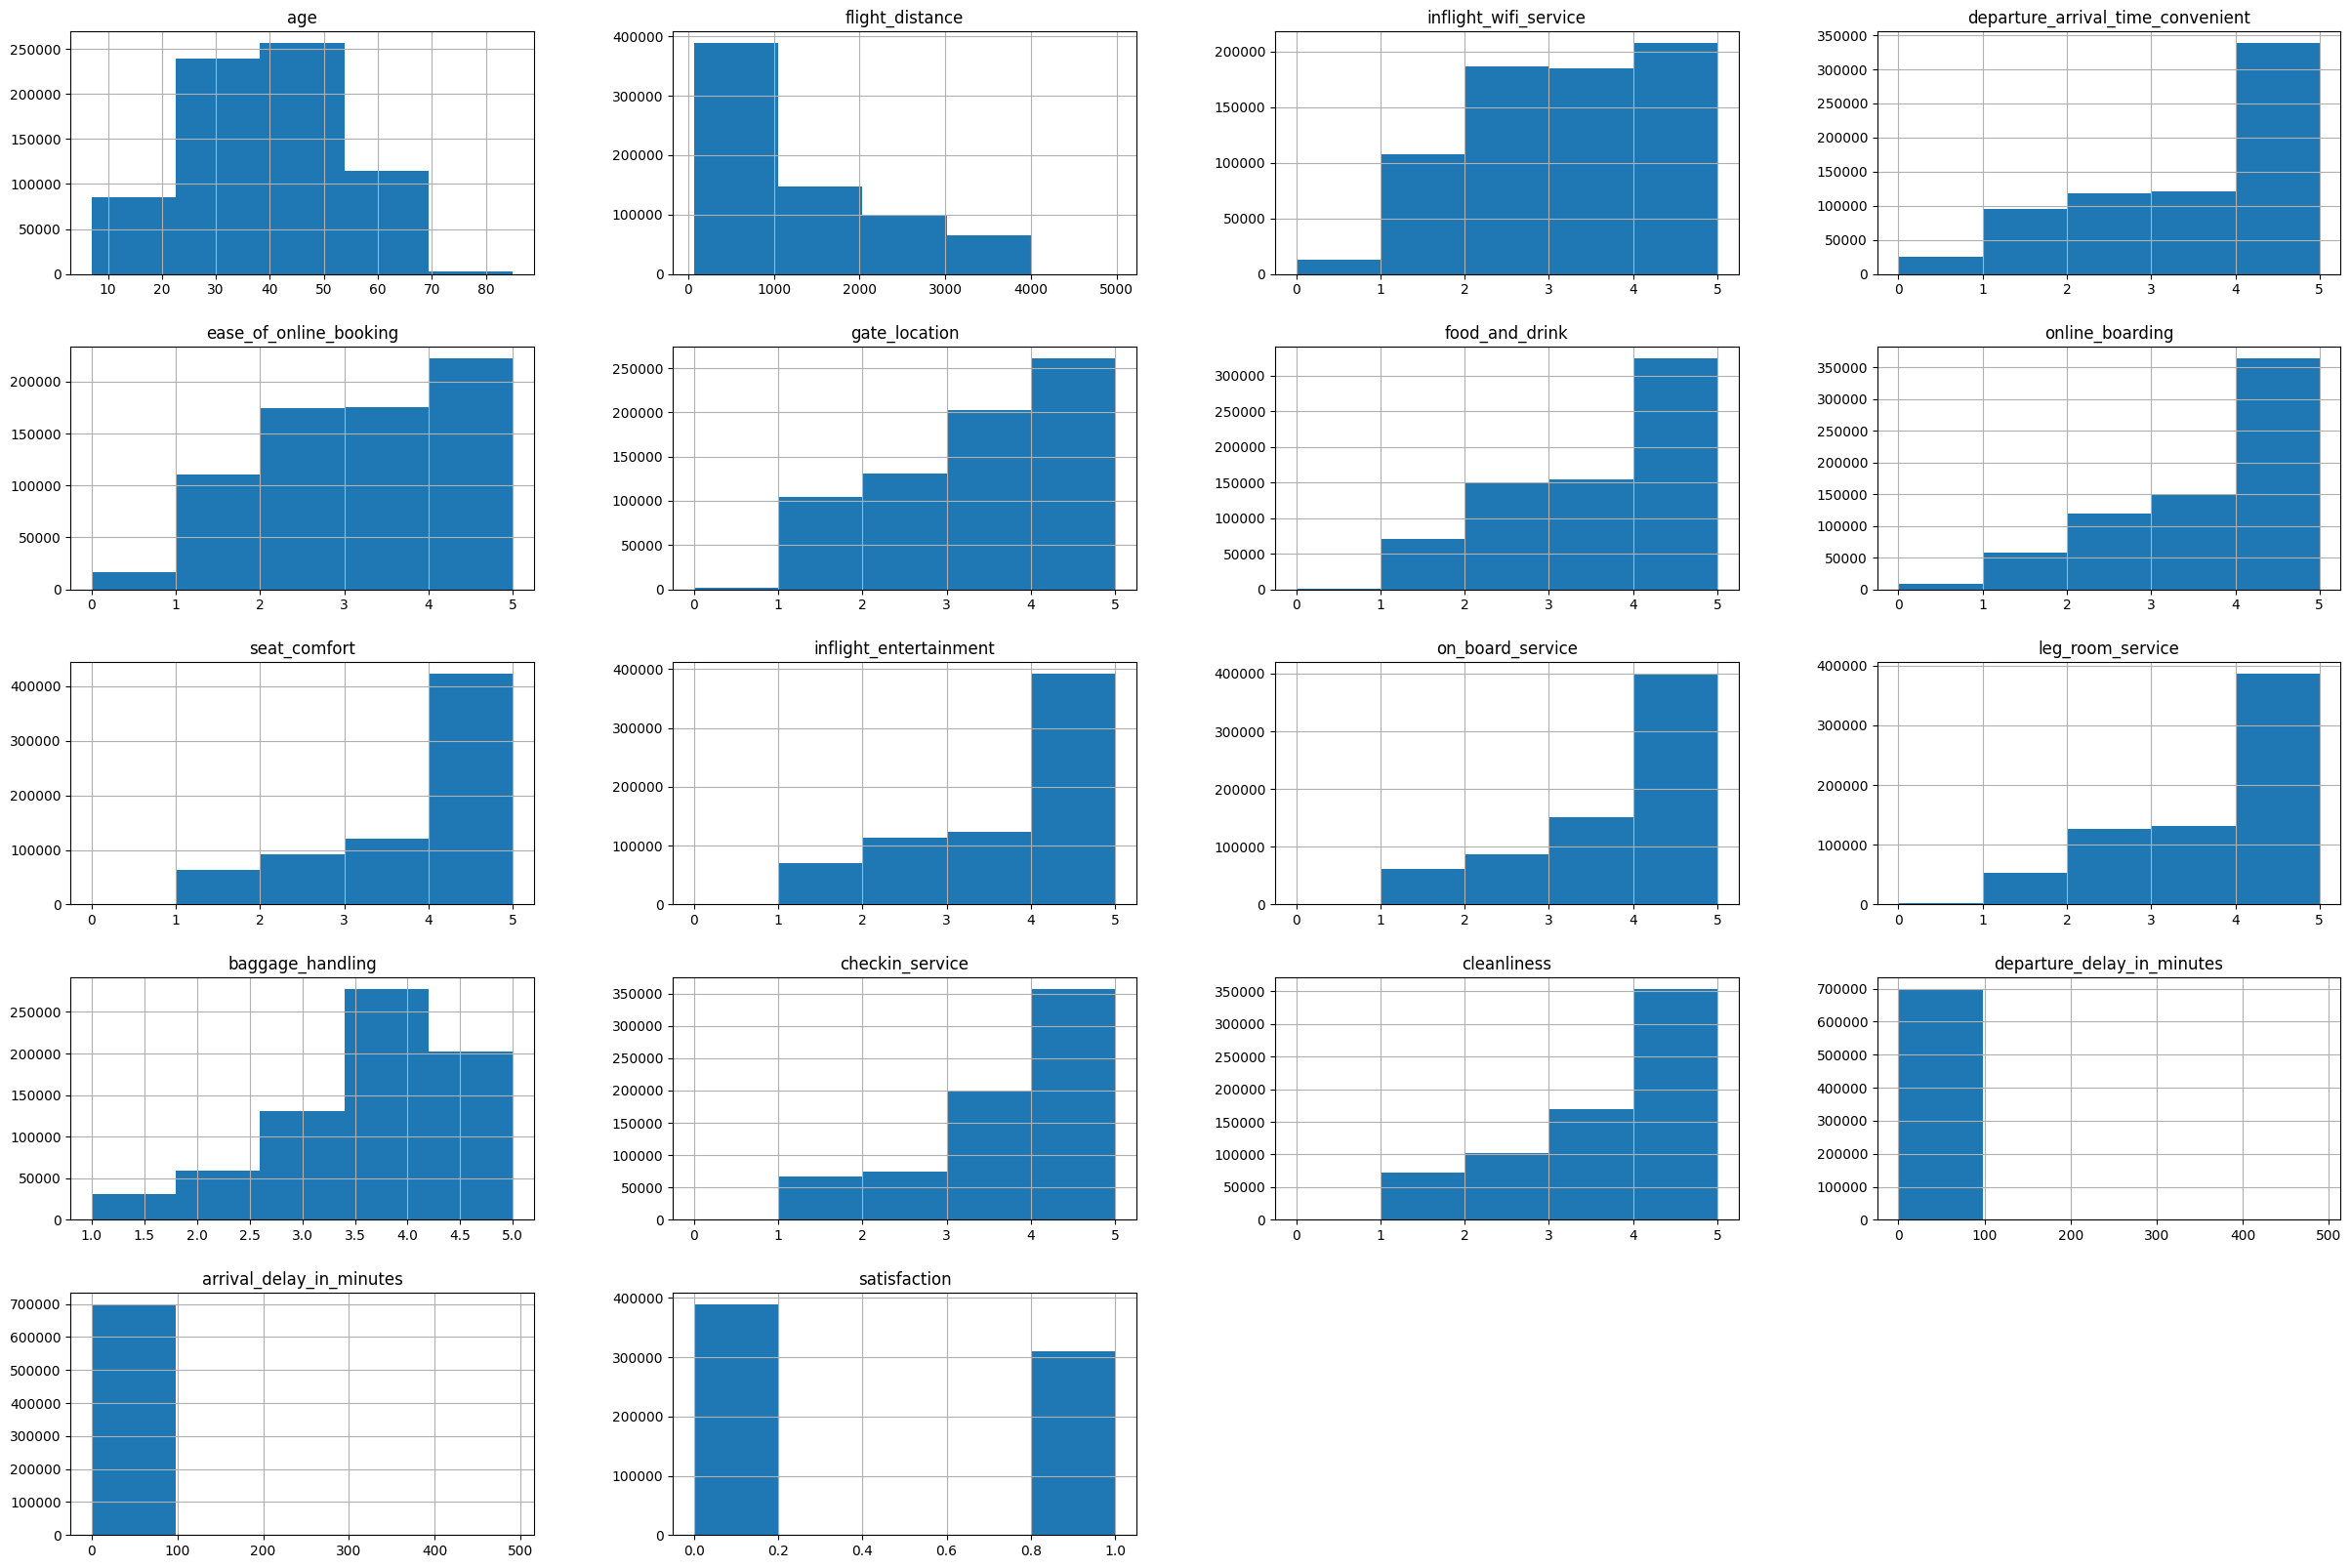

In [228]:
num_attributes.hist(bins=5, figsize=(30,20))

### 3.1.2 Categorical Variables

In [229]:
cat_attributes.head()

,gender,customer_type,type_of_travel,class
0,Female,Loyal Customer,Personal Travel,Eco
1,Male,Loyal Customer,Business travel,Business
2,Female,Loyal Customer,Personal Travel,Eco
3,Male,Loyal Customer,Personal Travel,Eco
4,Female,disloyal Customer,Business travel,Eco


In [230]:
cat_attributes.apply(lambda x: x.unique().shape[0])

gender            2
customer_type     2
type_of_travel    2
class             3
dtype: int64

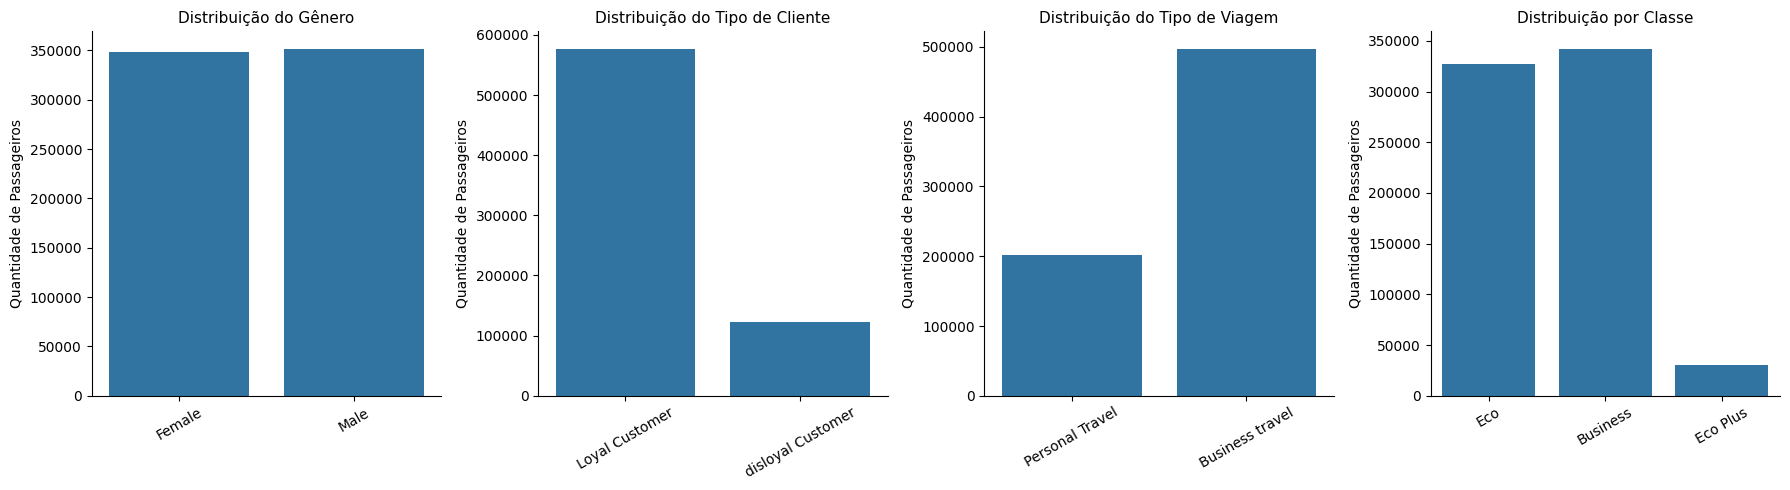

In [231]:
# Criar figura com 1 linha e 4 colunas
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# Lista das variáveis e seus títulos
variaveis = ['gender', 'customer_type', 'type_of_travel', 'class']

titulos = [
    'Distribuição do Gênero',
    'Distribuição do Tipo de Cliente',
    'Distribuição do Tipo de Viagem',
    'Distribuição por Classe'
]

# Criar os gráficos
for ax, variavel, titulo in zip(axes, variaveis, titulos):

    sns.countplot(data=df2,x=variavel,ax=ax)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('Quantidade de Passageiros')

    # Rotacionar rótulos, se necessário
    ax.tick_params(axis='x', rotation=30)

    # Remover bordas superiores e laterais
    sns.despine(ax=ax)

# Ajustar espaçamento
plt.tight_layout()

# Exibir os gráficos
plt.show()

## 3.2 Análise Exploratória Bivariada

### H1 Facilidade de autoserviço online de agendamento aumenta o nível de satisfação do cliente.

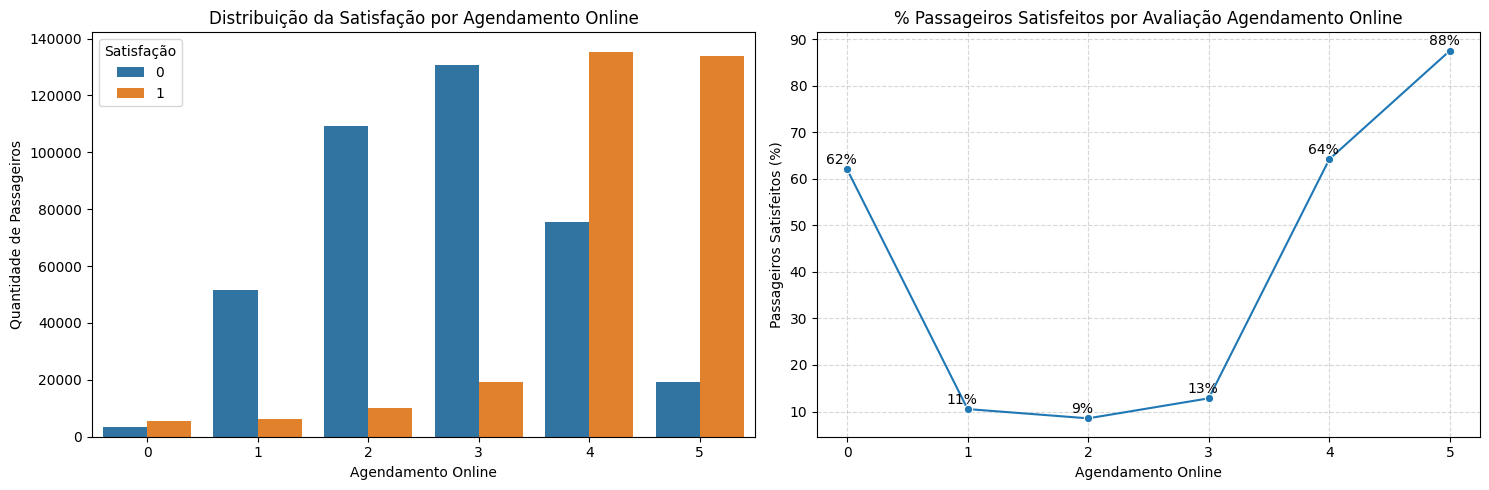

In [232]:
plt.figure(figsize=(15,5))

# Gráfico de agendamento online do vôo com Satisfação
plt.subplot( 1, 2 ,1)
sns.countplot(data=df2, x='online_boarding',hue='satisfaction')
plt.title('Distribuição da Satisfação por Agendamento Online')
plt.xlabel('Agendamento Online')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

plt.subplot( 1, 2 ,2)
# Calcular a porcentagem de passageiros satisfeitos por nota
df_plot = (df2.groupby('online_boarding').apply(lambda x: (x['satisfaction'] == 1).mean()*100,include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de linha com a porcentagem de passageiros satisfeitos por nota
sns.lineplot(data=df_plot, x='online_boarding', y='satisfacao_percentual',marker='o')
# Exibir o valor de cada ponto
for x, y in zip(df_plot['online_boarding'],df_plot['satisfacao_percentual']):
  plt.annotate(f'{y:.0f}%',(x, y),textcoords='offset points',xytext=(-4, 4),ha='center')
plt.title('% Passageiros Satisfeitos por Avaliação Agendamento Online')
plt.xlabel('Agendamento Online')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.xticks(sorted(df2['online_boarding'].dropna().unique()))
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### H2 O atraso na saída ou na chegada do vôo diminuem a satisfação do cliente.

**VERDADEIRA** O atraso na saída ou na chegada do vôo diminuem a satisfação do cliente.

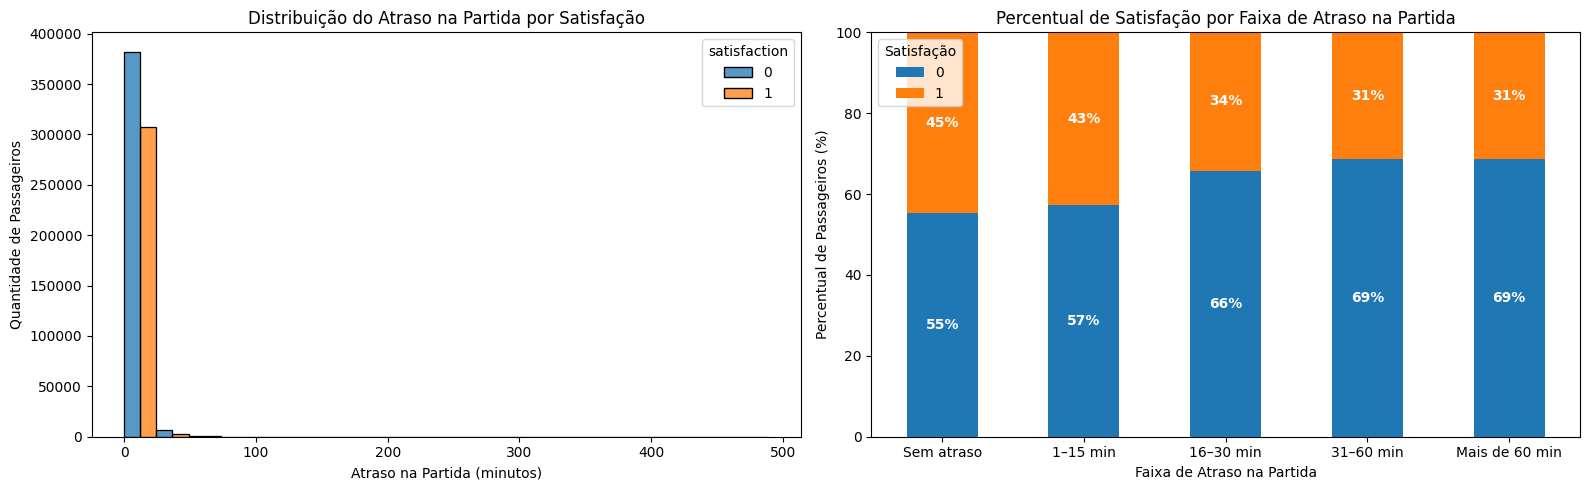

In [233]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico 1: Distribuição do atraso na partida
sns.histplot(data=df2,x='departure_delay_in_minutes',hue='satisfaction',bins=20,multiple='dodge',ax=axes[0])
axes[0].set_title('Distribuição do Atraso na Partida por Satisfação')
axes[0].set_xlabel('Atraso na Partida (minutos)')
axes[0].set_ylabel('Quantidade de Passageiros')

# Gráfico 2: Percentual de satisfação por faixa
# Criar faixas de atraso
limites = [-1, 0, 15, 30, 60, float('inf')]
rotulos = ['Sem atraso','1–15 min','16–30 min','31–60 min','Mais de 60 min']
df2['faixa_atraso_partida'] = pd.cut(df2['departure_delay_in_minutes'],bins=limites,labels=rotulos)

# Calcular percentual de cada categoria de satisfação
prop = pd.crosstab(df2['faixa_atraso_partida'],df2['satisfaction'],normalize='index') * 100

# Criar gráfico de barras empilhadas
prop.plot(kind='bar',stacked=True,ax=axes[1])

# Adicionar percentuais dentro das barras
for container in axes[1].containers:
    labels = [f'{v:.0f}%' if v >= 5 else''for v in container.datavalues]
    axes[1].bar_label(container,labels=labels,label_type='center',color='white',fontweight='bold')
axes[1].set_title('Percentual de Satisfação por Faixa de Atraso na Partida')
axes[1].set_xlabel('Faixa de Atraso na Partida')
axes[1].set_ylabel('Percentual de Passageiros (%)')
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Satisfação')

plt.tight_layout()
plt.show()

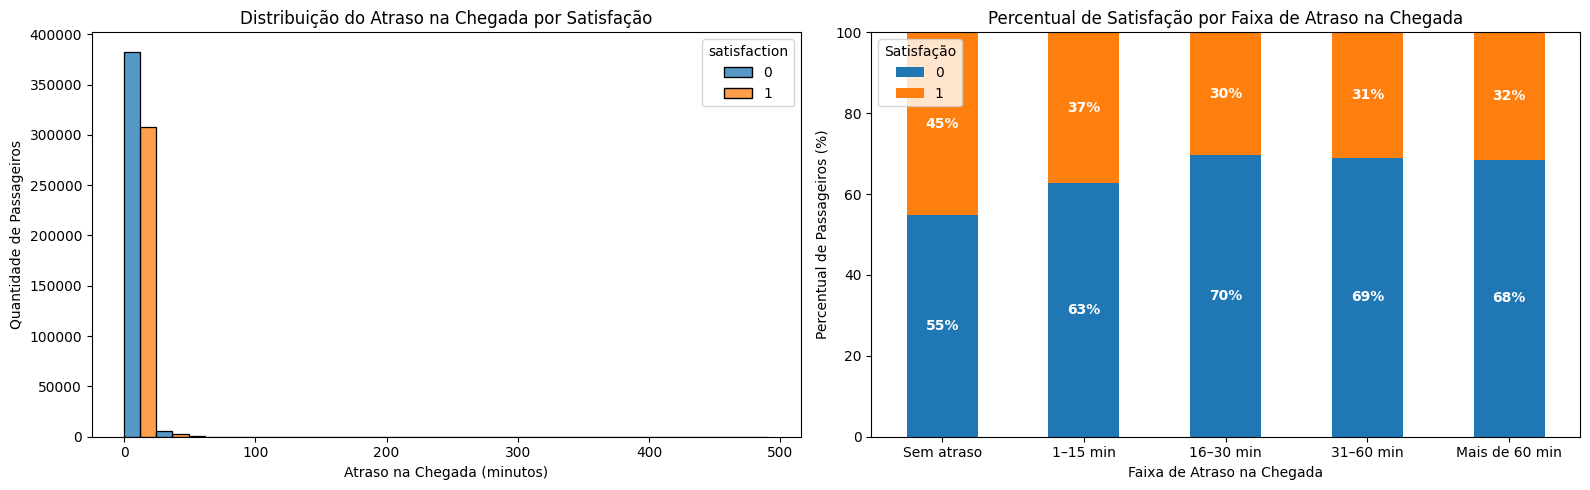

In [234]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico 1: Distribuição do atraso na chegada
sns.histplot(data=df2,x='arrival_delay_in_minutes',hue='satisfaction',bins=20,multiple='dodge',ax=axes[0])
axes[0].set_title('Distribuição do Atraso na Chegada por Satisfação')
axes[0].set_xlabel('Atraso na Chegada (minutos)')
axes[0].set_ylabel('Quantidade de Passageiros')

# Gráfico 2: Percentual de satisfação por faixa
# Criar faixas de atraso
limites = [-1, 0, 15, 30, 60, float('inf')]
rotulos = ['Sem atraso','1–15 min','16–30 min','31–60 min','Mais de 60 min']

df2['faixa_atraso_chegada'] = pd.cut(df2['arrival_delay_in_minutes'],bins=limites,labels=rotulos)

# Calcular percentual de cada categoria de satisfação
prop = pd.crosstab(df2['faixa_atraso_chegada'],df2['satisfaction'],normalize='index') * 100

# Criar gráfico de barras empilhadas
prop.plot(kind='bar',stacked=True,ax=axes[1])

# Adicionar percentuais dentro das barras
for container in axes[1].containers:
    labels = [f'{v:.0f}%' if v >= 5 else ''for v in container.datavalues]

    axes[1].bar_label(container,labels=labels,label_type='center',color='white',fontweight='bold')
axes[1].set_title('Percentual de Satisfação por Faixa de Atraso na Chegada')
axes[1].set_xlabel('Faixa de Atraso na Chegada')
axes[1].set_ylabel('Percentual de Passageiros (%)')
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Satisfação')

plt.tight_layout()
plt.show()

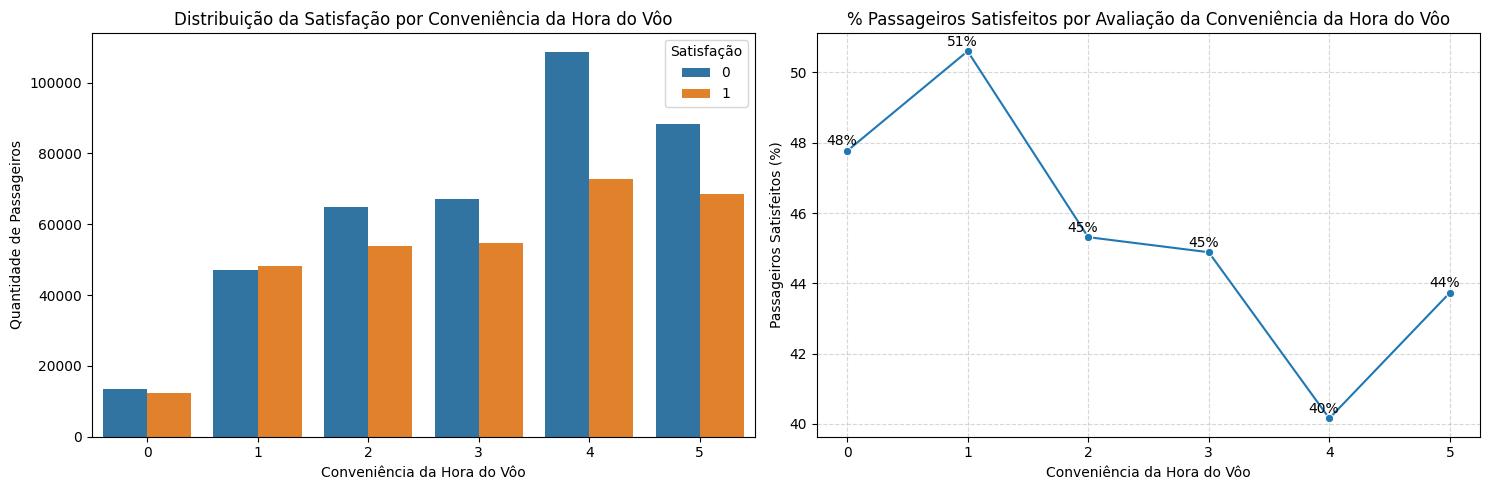

In [235]:
plt.figure(figsize=(15,5))

# Gráfico de Conveniência da Hora do Vôo com Satisfação
plt.subplot( 1, 2 ,1)
sns.countplot(data=df2, x='departure_arrival_time_convenient',hue='satisfaction')
plt.title('Distribuição da Satisfação por Conveniência da Hora do Vôo')
plt.xlabel('Conveniência da Hora do Vôo')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

plt.subplot( 1, 2 ,2)
# Calcular a porcentagem de passageiros satisfeitos por nota
df_plot = (df2.groupby('departure_arrival_time_convenient').apply(lambda x: (x['satisfaction'] == 1).mean()*100,include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de linha com a porcentagem de passageiros satisfeitos por nota
sns.lineplot(data=df_plot, x='departure_arrival_time_convenient', y='satisfacao_percentual',marker='o')
# Exibir o valor de cada ponto
for x, y in zip(df_plot['departure_arrival_time_convenient'],df_plot['satisfacao_percentual']):
  plt.annotate(f'{y:.0f}%',(x, y),textcoords='offset points',xytext=(-4, 4),ha='center')
plt.title('% Passageiros Satisfeitos por Avaliação da Conveniência da Hora do Vôo')
plt.xlabel('Conveniência da Hora do Vôo')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.xticks(sorted(df2['departure_arrival_time_convenient'].dropna().unique()))
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### H3 Distâncias maiores de vôo diminuem a satisfação do cliente.

**FALSA** Distâncias maiores de vôo não diminuem a satisfação do cliente.

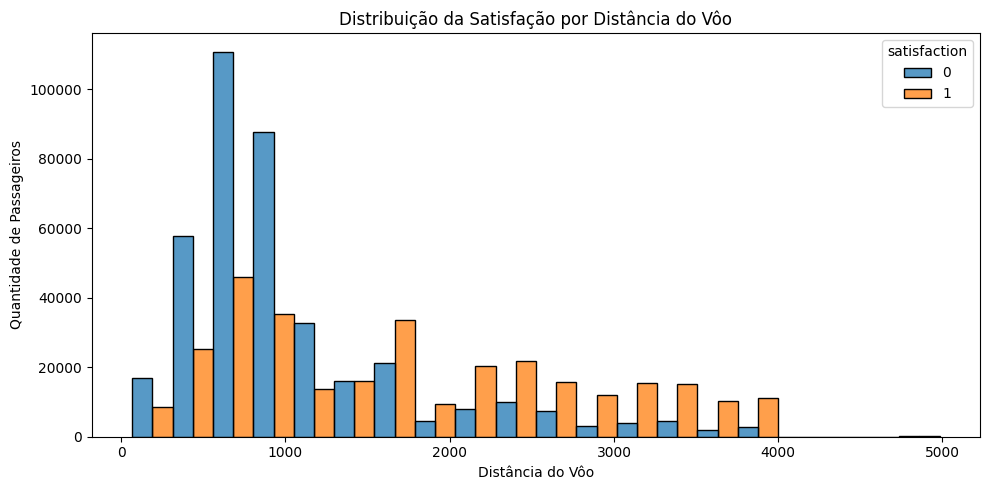

In [236]:
# Histograma da distância do voo com a satisfação
plt.figure(figsize=(10,5))
sns.histplot(data=df2, x='flight_distance', hue='satisfaction',bins=20, multiple='dodge')
plt.title('Distribuição da Satisfação por Distância do Vôo')
plt.xlabel('Distância do Vôo')
plt.ylabel('Quantidade de Passageiros')

plt.tight_layout()
plt.show()


<Figure size 500x500 with 0 Axes>

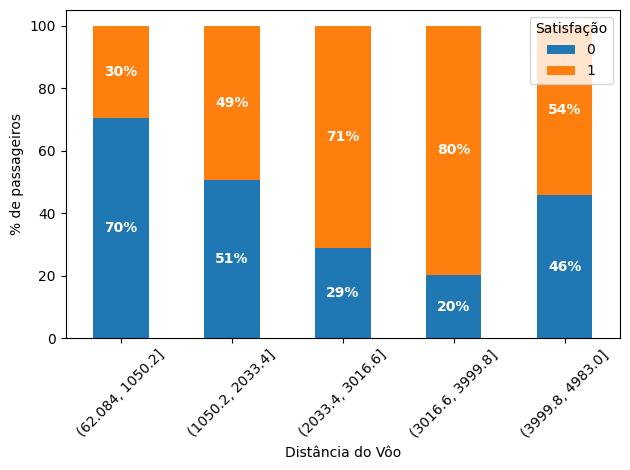

In [237]:
#proporção de satisfeitos por faixa
plt.figure(figsize=(5,5))
faixas = pd.cut(df2['flight_distance'], bins=5)
prop = pd.crosstab(faixas, df2['satisfaction'], normalize='index') * 100
ax = prop.plot(kind='bar', stacked=True)

# Porcentagem dentro de cada segmento das barras
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', label_type='center',color='white', fontweight='bold')

plt.ylabel('% de passageiros')
plt.xlabel('Distância do Vôo')
plt.xticks(rotation=45)
plt.legend(title='Satisfação')

plt.tight_layout()
plt.show()


### H4 Quanto maior a satisfação com o serviço a bordo maior a satisfação do cliente.

**VERDADEIRA** Quanto maior a satisfação com o serviçoa bordo maior a satisfação do cliente.

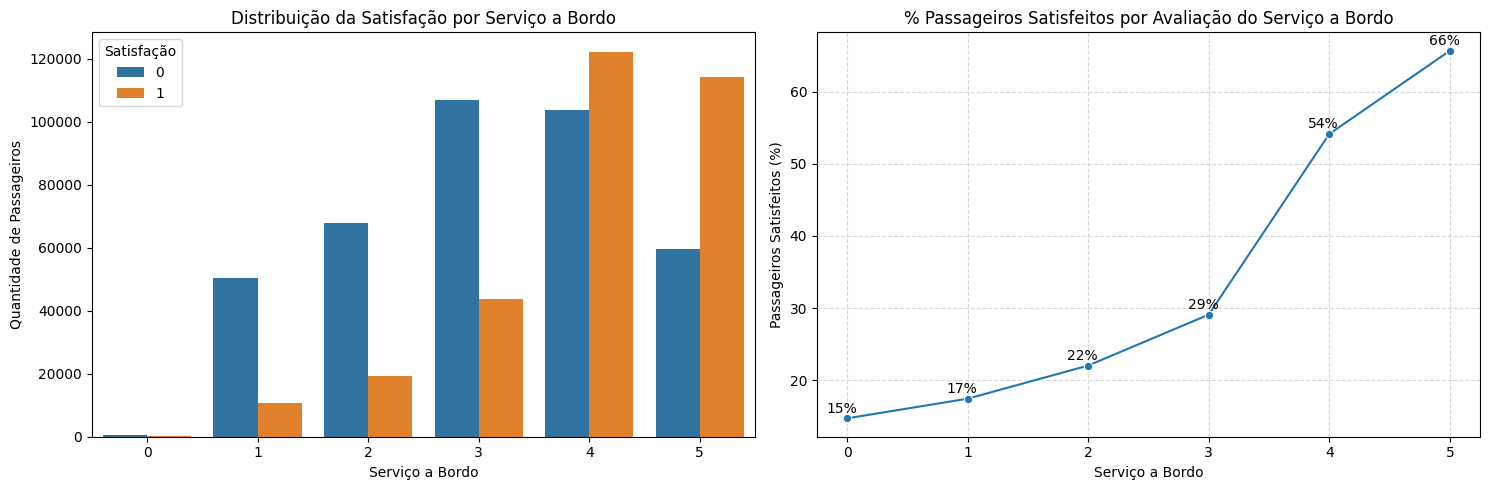

In [238]:
plt.figure(figsize=(15,5))

# Gráfico de atraso do vôo com Satisfação
plt.subplot( 1, 2 ,1)
sns.countplot(data=df2, x='on_board_service',hue='satisfaction')
plt.title('Distribuição da Satisfação por Serviço a Bordo')
plt.xlabel('Serviço a Bordo')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

plt.subplot( 1, 2 ,2)
# Calcular a porcentagem de passageiros satisfeitos por nota
df_plot = (df2.groupby('on_board_service').apply(lambda x: (x['satisfaction'] == 1).mean()*100,include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de linha com a porcentagem de passageiros satisfeitos por nota
sns.lineplot(data=df_plot, x='on_board_service', y='satisfacao_percentual',marker='o')
# Exibir o valor de cada ponto
for x, y in zip(df_plot['on_board_service'],df_plot['satisfacao_percentual']):
  plt.annotate(f'{y:.0f}%',(x, y),textcoords='offset points',xytext=(-4, 4),ha='center')
plt.title('% Passageiros Satisfeitos por Avaliação do Serviço a Bordo')
plt.xlabel('Serviço a Bordo')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.xticks(sorted(df2['on_board_service'].dropna().unique()))
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### H5 Quanto maior a satisfação com o serviço de wifi a bordo maior a satisfação do cliente.

**VERDADEIRA** Quanto maior a satisfação com serviço de wifi a bordo maior a satisfação do cliente.

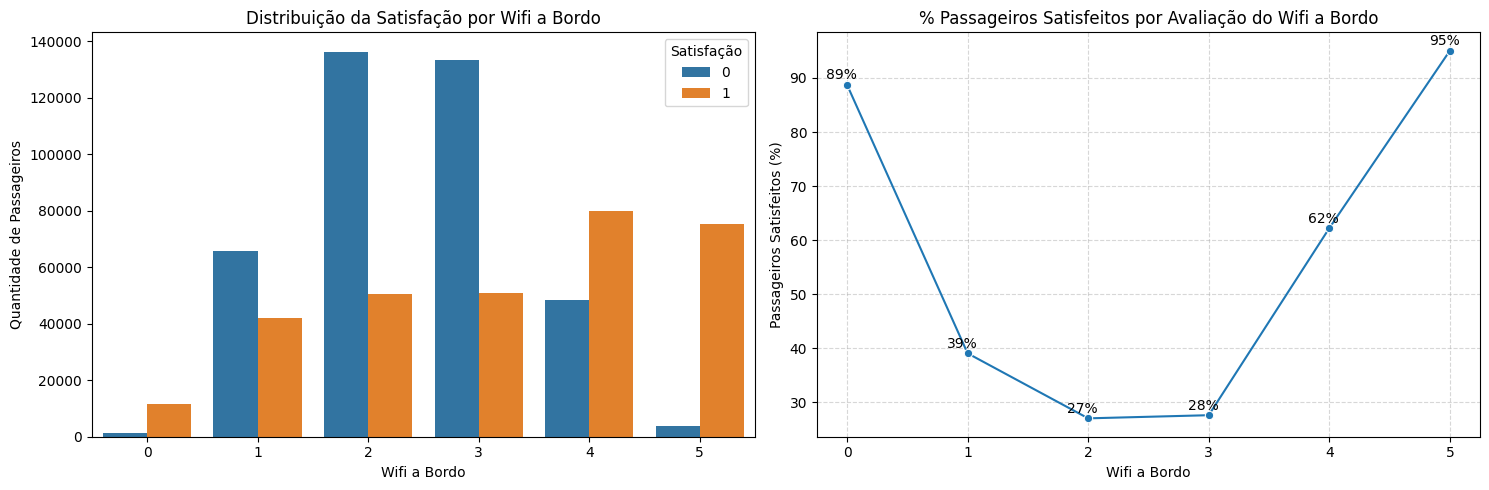

In [239]:
plt.figure(figsize=(15,5))

# Gráfico de Wifi a bordo com Satisfação
plt.subplot( 1, 2 ,1)
sns.countplot(data=df2, x='inflight_wifi_service',hue='satisfaction')
plt.title('Distribuição da Satisfação por Wifi a Bordo')
plt.xlabel('Wifi a Bordo')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

plt.subplot( 1, 2 ,2)
# Calcular a porcentagem de passageiros satisfeitos por nota
df_plot = (df2.groupby('inflight_wifi_service').apply(lambda x: (x['satisfaction'] == 1).mean()*100,include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de linha com a porcentagem de passageiros satisfeitos por nota
sns.lineplot(data=df_plot, x='inflight_wifi_service', y='satisfacao_percentual',marker='o')
# Exibir o valor de cada ponto
for x, y in zip(df_plot['inflight_wifi_service'],df_plot['satisfacao_percentual']):
  plt.annotate(f'{y:.0f}%',(x, y),textcoords='offset points',xytext=(-4, 4),ha='center')
plt.title('% Passageiros Satisfeitos por Avaliação do Wifi a Bordo')
plt.xlabel('Wifi a Bordo')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.xticks(sorted(df2['inflight_wifi_service'].dropna().unique()))
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### H6 Quanto maior a satisfação com o serviço de entretenimento a bordo maior a satisfação do cliente.

**VERDADEIRA** Quanto maior a satisfação com o serviço deentretenimento a bordo maior a satisfação do cliente.

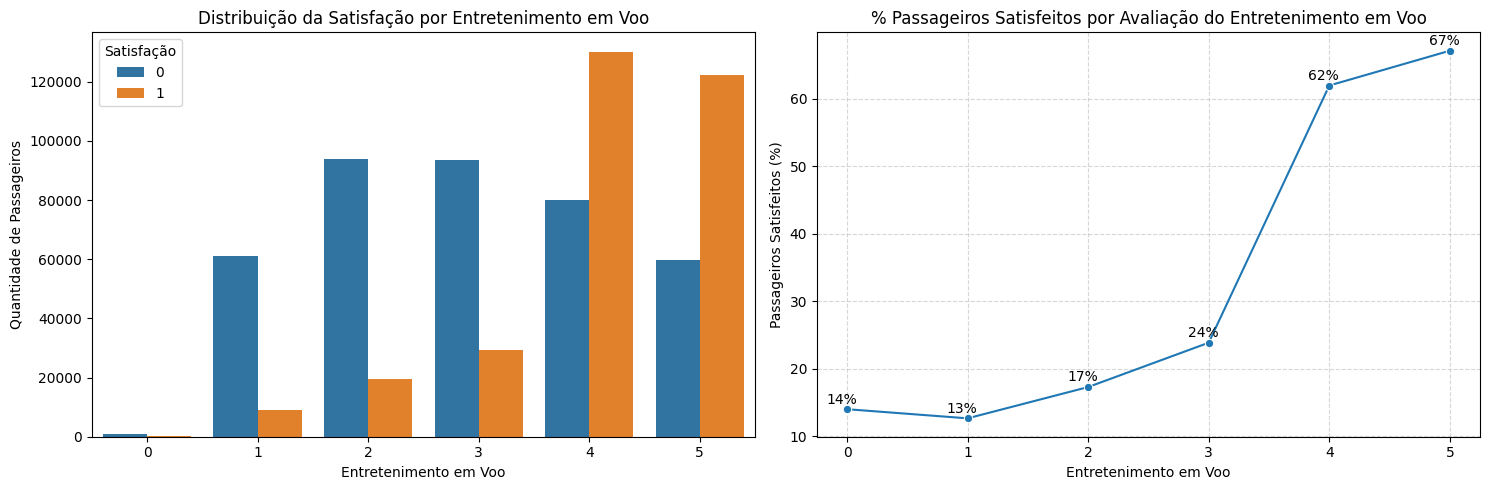

In [240]:
plt.figure(figsize=(15,5))

# Gráfico de atraso do vôo com Satisfação
plt.subplot( 1, 2 ,1)
sns.countplot(data=df2, x='inflight_entertainment',hue='satisfaction')
plt.title('Distribuição da Satisfação por Entretenimento em Voo')
plt.xlabel('Entretenimento em Voo')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

plt.subplot( 1, 2 ,2)
# Calcular a porcentagem de passageiros satisfeitos por nota
df_plot = (df2.groupby('inflight_entertainment').apply(lambda x: (x['satisfaction'] == 1).mean()*100,include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de linha com a porcentagem de passageiros satisfeitos por nota
sns.lineplot(data=df_plot, x='inflight_entertainment', y='satisfacao_percentual',marker='o')
# Exibir o valor de cada ponto
for x, y in zip(df_plot['inflight_entertainment'],df_plot['satisfacao_percentual']):
  plt.annotate(f'{y:.0f}%',(x, y),textcoords='offset points',xytext=(-4, 4),ha='center')
plt.title('% Passageiros Satisfeitos por Avaliação do Entretenimento em Voo')
plt.xlabel('Entretenimento em Voo')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.xticks(sorted(df2['inflight_entertainment'].dropna().unique()))
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### H7 Quanto maior a satisfação com o conforto do assento maior a satisfação do cliente.

**VERDADEIRA** Quanto maior a satisfação com o conforto do assento maior a satisfação do cliente.

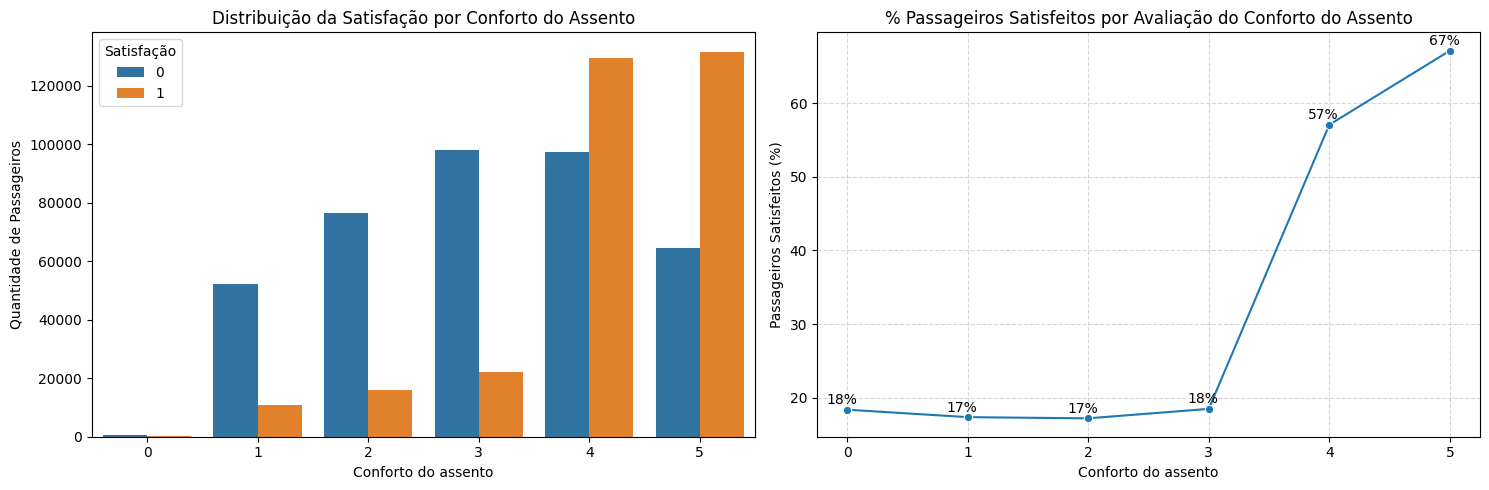

In [241]:
plt.figure(figsize=(15,5))

# Gráfico de Conforto do Assento com Satisfação
plt.subplot( 1, 2 ,1)
sns.countplot(data=df2, x='seat_comfort',hue='satisfaction')
plt.title('Distribuição da Satisfação por Conforto do Assento')
plt.xlabel('Conforto do assento')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

plt.subplot( 1, 2 ,2)
# Calcular a porcentagem de passageiros satisfeitos por nota
df_plot = (df2.groupby('seat_comfort').apply(lambda x: (x['satisfaction'] == 1).mean()*100,include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de linha com a porcentagem de passageiros satisfeitos por nota
sns.lineplot(data=df_plot, x='seat_comfort', y='satisfacao_percentual',marker='o')
# Exibir o valor de cada ponto
for x, y in zip(df_plot['seat_comfort'],df_plot['satisfacao_percentual']):
  plt.annotate(f'{y:.0f}%',(x, y),textcoords='offset points',xytext=(-4, 4),ha='center')
plt.title('% Passageiros Satisfeitos por Avaliação do Conforto do Assento')
plt.xlabel('Conforto do assento')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.xticks(sorted(df2['seat_comfort'].dropna().unique()))
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### H8 Quanto maior a satisfação com o serviço de limpeza a bordo maior a satisfação do cliente.

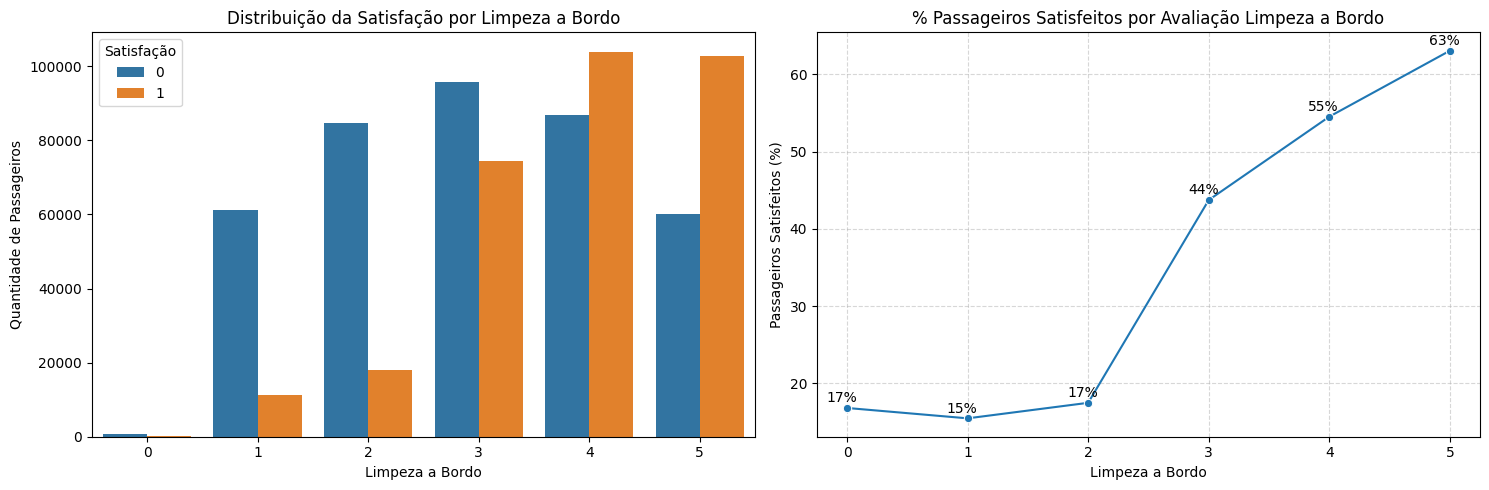

In [242]:
plt.figure(figsize=(15,5))

# Gráfico de Limpeza a Bordo com Satisfação
plt.subplot( 1, 2 ,1)
sns.countplot(data=df2, x='cleanliness',hue='satisfaction')
plt.title('Distribuição da Satisfação por Limpeza a Bordo')
plt.xlabel('Limpeza a Bordo')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

plt.subplot( 1, 2 ,2)
# Calcular a porcentagem de passageiros satisfeitos por nota
df_plot = (df2.groupby('cleanliness').apply(lambda x: (x['satisfaction'] == 1).mean()*100,include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de linha com a porcentagem de passageiros satisfeitos por nota
sns.lineplot(data=df_plot, x='cleanliness', y='satisfacao_percentual',marker='o')
# Exibir o valor de cada ponto
for x, y in zip(df_plot['cleanliness'],df_plot['satisfacao_percentual']):
  plt.annotate(f'{y:.0f}%',(x, y),textcoords='offset points',xytext=(-4, 4),ha='center')
plt.title('% Passageiros Satisfeitos por Avaliação Limpeza a Bordo')
plt.xlabel('Limpeza a Bordo')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.xticks(sorted(df2['cleanliness'].dropna().unique()))
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### H9 A classe de viajante Eco tem menor nível de satisfação.

 **VERDADEIRA** A classe de viajante ECO tem menor nível de satisfação.

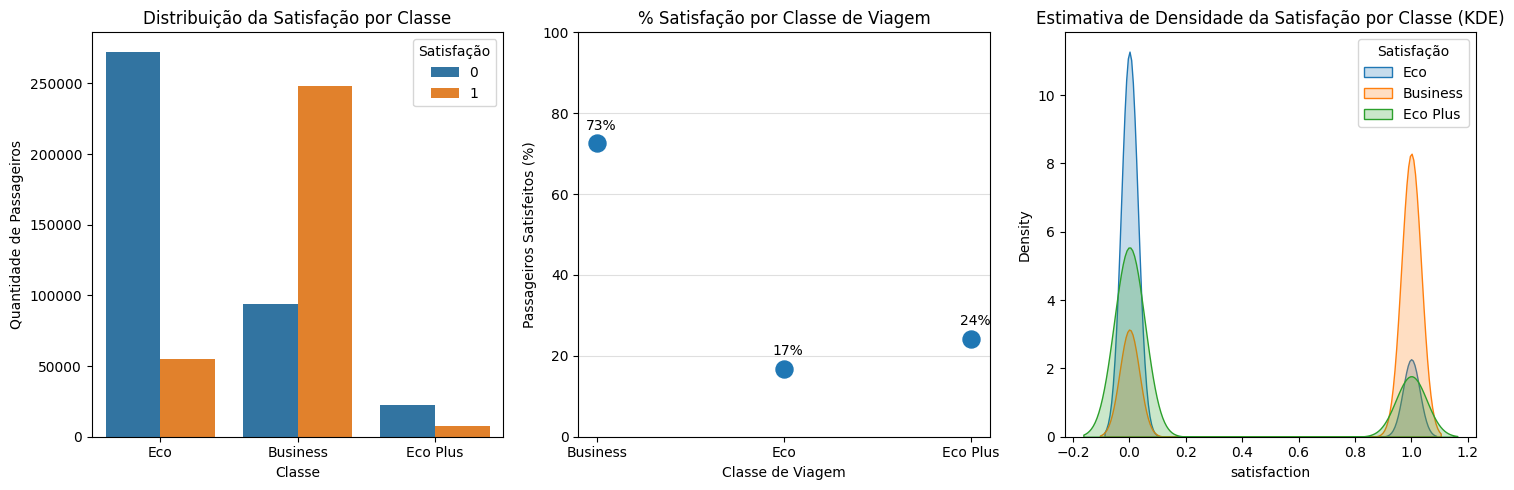

In [243]:
plt.figure(figsize=(15,5))

# Gráfico de Classe com Satisfação
plt.subplot( 1, 3 ,1)
sns.countplot(data=df2, x='class',hue='satisfaction')
plt.title('Distribuição da Satisfação por Classe')
plt.xlabel('Classe')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

# Gráfico de pontos Classe com Satisfação
plt.subplot( 1, 3 ,2)
# Calcular a taxa de satisfação por classe
resultado = (df2.groupby('class').apply(lambda x: (x['satisfaction'] == 1).mean()*100, include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de dispersão com a taxa de satisfação por classe
plt.scatter(resultado['class'],resultado['satisfacao_percentual'],s=150)
# Mostrar o percentual acima de cada ponto
for _, row in resultado.iterrows():
    plt.annotate(f"{row['satisfacao_percentual']:.0f}%",(row['class'], row['satisfacao_percentual']),xytext=(3, 10),textcoords='offset points',ha='center')

plt.title('% Satisfação por Classe de Viagem')
plt.xlabel('Classe de Viagem')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.4)

# Gráfico de Classe com Satisfação (KDE)
plt.subplot( 1, 3 ,3)
sns.kdeplot( df2[df2['class'] == 'Eco']['satisfaction'], label='Eco', fill=True )
sns.kdeplot( df2[df2['class'] == 'Business']['satisfaction'], label='Business', fill=True )
sns.kdeplot( df2[df2['class'] == 'Eco Plus']['satisfaction'], label='Eco Plus', fill=True )
plt.title('Estimativa de Densidade da Satisfação por Classe (KDE)')
plt.legend(title='Satisfação')

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### H10 O cliente fidelizado tem maior nível de satisfação.

**VERDADEIRA** O cliente fidelizado tem maior nível de satisfação.

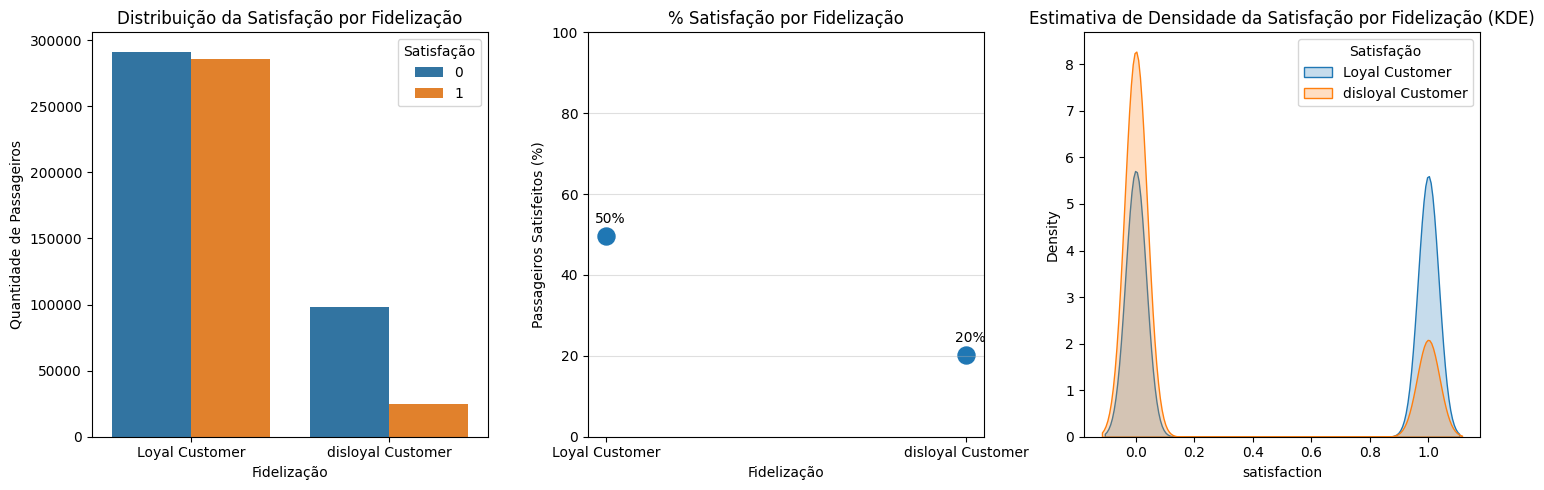

In [244]:
plt.figure(figsize=(15,5))

# Gráfico de Fidelização com Satisfação
plt.subplot( 1, 3 ,1)
sns.countplot(data=df2, x='customer_type',hue='satisfaction')
plt.title('Distribuição da Satisfação por Fidelização')
plt.xlabel('Fidelização')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

# Gráfico de pontos Fidelização com Satisfação
plt.subplot( 1, 3 ,2)
# Calcular a taxa de satisfação por Fidelização
resultado = (df2.groupby('customer_type').apply(lambda x: (x['satisfaction'] == 1).mean()*100, include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de dispersão com a taxa de satisfação por Fidelização
plt.scatter(resultado['customer_type'],resultado['satisfacao_percentual'],s=150)
# Mostrar o percentual acima de cada ponto
for _, row in resultado.iterrows():
    plt.annotate(f"{row['satisfacao_percentual']:.0f}%",(row['customer_type'], row['satisfacao_percentual']),xytext=(3, 10),textcoords='offset points',ha='center')

plt.title('% Satisfação por Fidelização')
plt.xlabel('Fidelização')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.4)

# Gráfico de Fidelização com Satisfação (KDE)
plt.subplot( 1, 3 ,3)
sns.kdeplot( df2[df2['customer_type'] == 'Loyal Customer']['satisfaction'], label='Loyal Customer', fill=True )
sns.kdeplot( df2[df2['customer_type'] == 'disloyal Customer']['satisfaction'], label='disloyal Customer', fill=True )
plt.title('Estimativa de Densidade da Satisfação por Fidelização (KDE)')
plt.legend(title='Satisfação')

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### H11 Viajantes a trabalho tem maior nível de satisfação.

**VERDADEIRA** Viajantas a trabalho tem maior nível de satisfação.

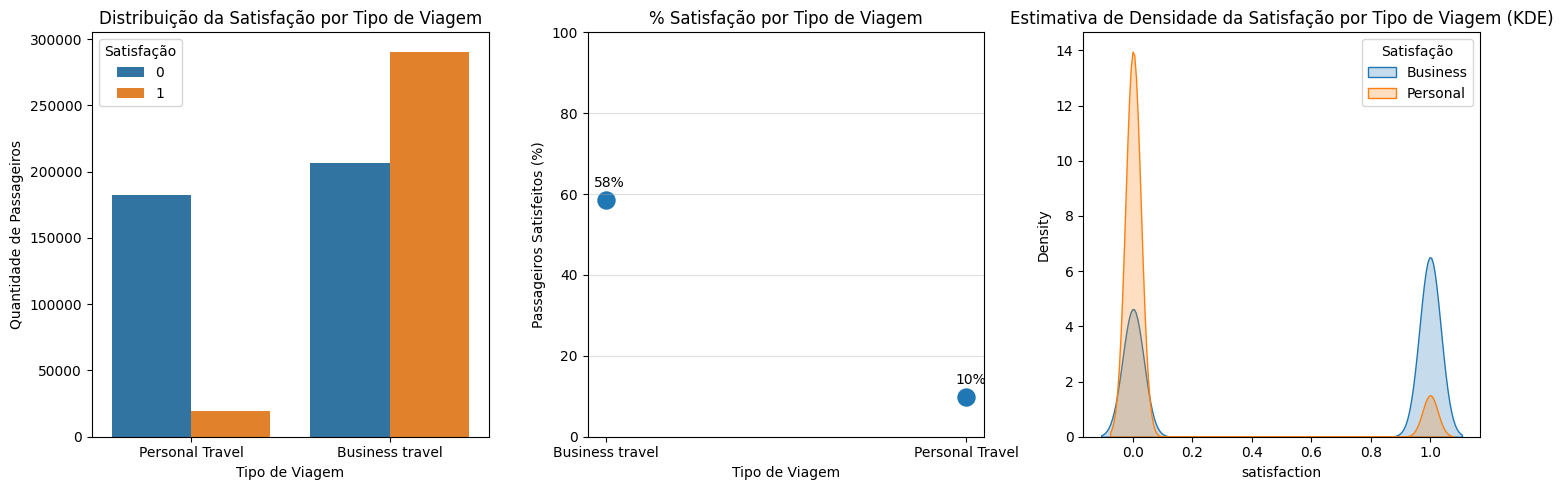

In [245]:
plt.figure(figsize=(15,5))

# Gráfico de Tipo de Viagem com Satisfação
plt.subplot( 1, 3 ,1)
sns.countplot(data=df2, x='type_of_travel',hue='satisfaction')
plt.title('Distribuição da Satisfação por Tipo de Viagem')
plt.xlabel('Tipo de Viagem')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

# Gráfico de pontos Tipo de Viagem com Satisfação
plt.subplot( 1, 3 ,2)
# Calcular a taxa de satisfação por Tipo de Viagem
resultado = (df2.groupby('type_of_travel').apply(lambda x: (x['satisfaction'] == 1).mean()*100, include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de dispersão com a taxa de satisfação por Tipo de Viagem
plt.scatter(resultado['type_of_travel'],resultado['satisfacao_percentual'],s=150)
# Mostrar o percentual acima de cada ponto
for _, row in resultado.iterrows():
    plt.annotate(f"{row['satisfacao_percentual']:.0f}%",(row['type_of_travel'], row['satisfacao_percentual']),xytext=(3, 10),textcoords='offset points',ha='center')

plt.title('% Satisfação por Tipo de Viagem')
plt.xlabel('Tipo de Viagem')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.4)

# Gráfico de Tipo de Viagem com Satisfação (KDE)
plt.subplot( 1, 3 ,3)
sns.kdeplot( df2[df2['type_of_travel'] == 'Business travel']['satisfaction'], label='Business', fill=True )
sns.kdeplot( df2[df2['type_of_travel'] == 'Personal Travel']['satisfaction'], label='Personal', fill=True )
plt.title('Estimativa de Densidade da Satisfação por Tipo de Viagem (KDE)')
plt.legend(title='Satisfação')

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### 3.2.1 Resumo das Hipóteses

In [246]:
tab =[['Hipóteses', 'Conclusão', 'Relevancia'],
['H1', 'Verdadeira', 'Alta'],
['H2', 'Verdadeira', 'Baixa'],
['H3', 'Falsa', 'Baixa'],
['H4', 'Verdadeira', 'Baixa'],
['H5', 'Verdadeira', 'Média'],
['H6', 'Verdadeira', 'Alta'],
['H7', 'Verdadeira', 'Média'],
['H8', 'Verdadeira', 'Alta'],
['H9', 'Verdadeira', 'Alta'],
['H10', 'Verdadeira', 'Baixa'],
['H11', 'Verdadeira', 'Alta']
]
print( tabulate( tab, headers='firstrow' ) )

Hipóteses    Conclusão    Relevancia
-----------  -----------  ------------
H1           Verdadeira   Alta
H2           Verdadeira   Baixa
H3           Falsa        Baixa
H4           Verdadeira   Baixa
H5           Verdadeira   Média
H6           Verdadeira   Alta
H7           Verdadeira   Média
H8           Verdadeira   Alta
H9           Verdadeira   Alta
H10          Verdadeira   Baixa
H11          Verdadeira   Alta


## 3.3 Análise Multivariada

### 3.3.1 Numerical Attributes 

In [247]:
# Atributos numéricos
num_attributes.head()

,age,flight_distance,inflight_wifi_service,departure_arrival_time_convenient,ease_of_online_booking,gate_location,food_and_drink,online_boarding,seat_comfort,inflight_entertainment,on_board_service,leg_room_service,baggage_handling,checkin_service,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,satisfaction
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,1
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,0
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,0
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,0


<Axes: >

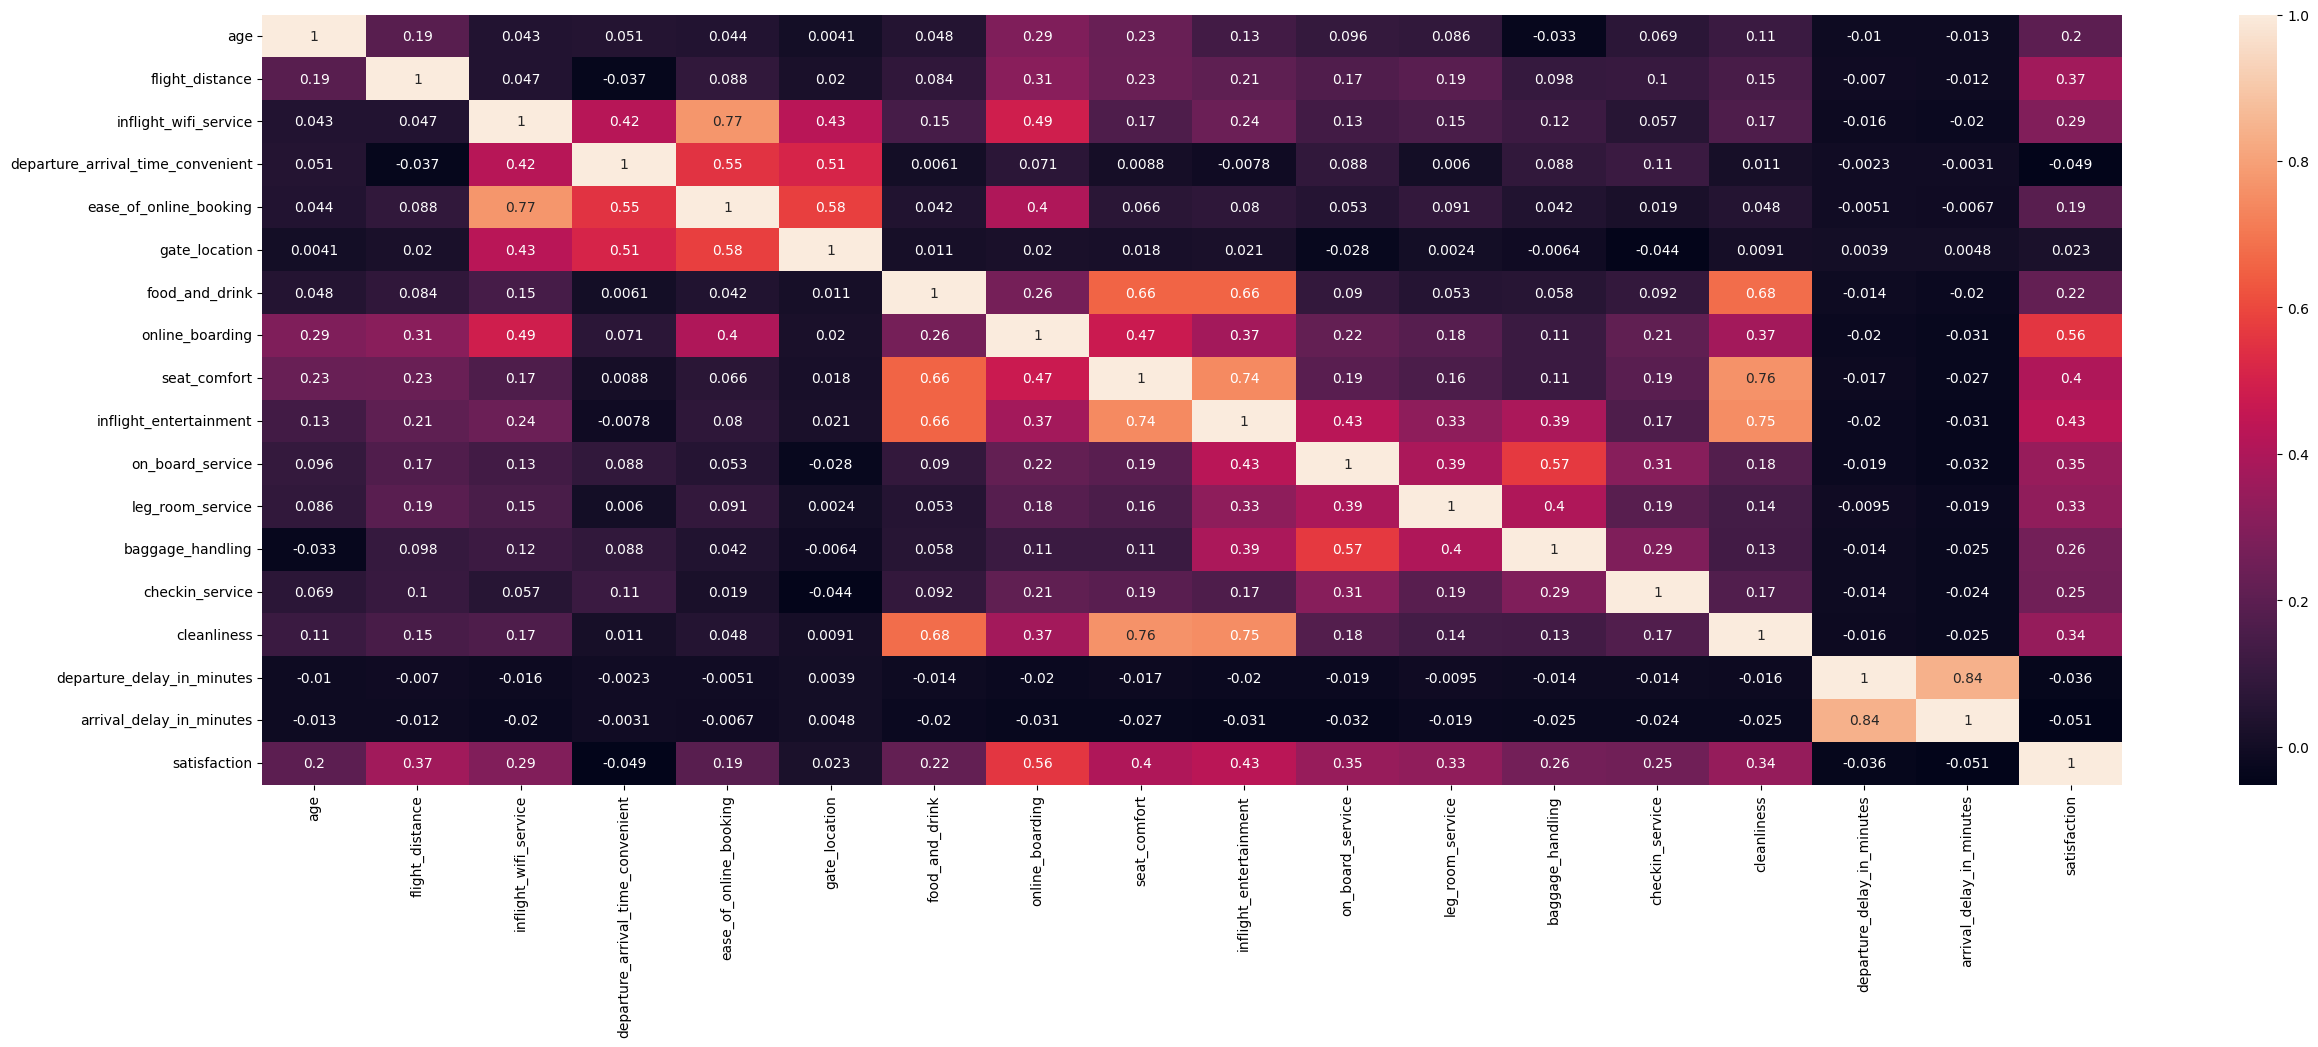

In [248]:
# Gráfico de Correlação
plt.figure(figsize=(30, 10))
correlation = num_attributes.corr(method='pearson')
sns.heatmap(correlation, annot=True)

### 3.3.2 Categorical Attributes

In [249]:
# Atributos categóricos
cat_attributes.head()

,gender,customer_type,type_of_travel,class
0,Female,Loyal Customer,Personal Travel,Eco
1,Male,Loyal Customer,Business travel,Business
2,Female,Loyal Customer,Personal Travel,Eco
3,Male,Loyal Customer,Personal Travel,Eco
4,Female,disloyal Customer,Business travel,Eco


In [250]:
# Criando um Dicionário Cramer V
def cramer_v (x,y):
    cm = pd.crosstab(x,y).to_numpy()
    n = cm.sum()
    r, k =cm.shape

    chi2 = ss.chi2_contingency(cm)[0]
    chi2corr = bt.max(0,chi2-(k-1)*(n-1)/(n-1))
    kcorr = k- (k-1)**2/(n-1)
    rcorr = r- (r-1)**2/(n-1)

    return np.sqrt((chi2corr/n)/(bt.min(kcorr-1, rcorr-1)))

In [251]:
# Cramer V (cm): Matriz de confusão: todas as combinações entre as variáveis categóricas
a1 = cramer_v(cat_attributes['class'], cat_attributes['class'])
a2 = cramer_v(cat_attributes['class'], cat_attributes['type_of_travel'])
a3 = cramer_v(cat_attributes['class'], cat_attributes['customer_type'])
a4 = cramer_v(cat_attributes['class'], cat_attributes['gender'])

a5 = cramer_v(cat_attributes['type_of_travel'], cat_attributes['class'])
a6 = cramer_v(cat_attributes['type_of_travel'], cat_attributes['type_of_travel'])
a7 = cramer_v(cat_attributes['type_of_travel'], cat_attributes['customer_type'])
a8 = cramer_v(cat_attributes['type_of_travel'], cat_attributes['gender'])

a9 = cramer_v(cat_attributes['customer_type'], cat_attributes['class'])
a10 = cramer_v(cat_attributes['customer_type'], cat_attributes['type_of_travel'])
a11 = cramer_v(cat_attributes['customer_type'], cat_attributes['customer_type'])
a12 = cramer_v(cat_attributes['customer_type'], cat_attributes['gender'])

a13 = cramer_v(cat_attributes['gender'], cat_attributes['class'])
a14 = cramer_v(cat_attributes['gender'], cat_attributes['type_of_travel'])
a15 = cramer_v(cat_attributes['gender'], cat_attributes['customer_type'])
a16 = cramer_v(cat_attributes['gender'], cat_attributes['gender'])

# Dataset final
d = pd.DataFrame({
  'class': [a1,a2,a3,a4],
  'type_of_travel': [a5,a6,a7,a8],
  'customer_type': [a9,a10,a11,a12],
  'gender': [a13,a14,a15,a16]})

d = d.set_index(d.columns)
d

,class,type_of_travel,customer_type,gender
class,1.000001,0.602674,0.143182,0.009528
type_of_travel,0.602675,0.999997,0.293060,0.024234
customer_type,0.143187,0.293060,0.999995,0.055909
gender,0.009603,0.024234,0.055909,0.999997


<Axes: >

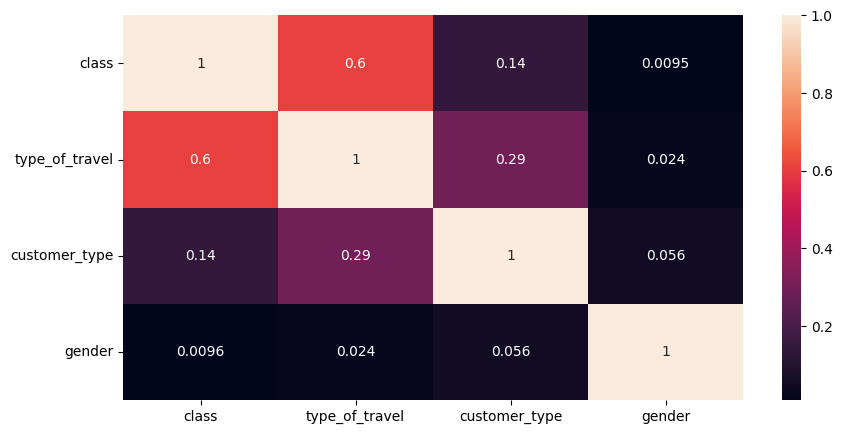

In [252]:
# Gráfico Cramer V (cm)
plt.figure(figsize=(10, 5))
sns.heatmap(d, annot=True)

# 4.0 Data Preparation 

## 4.1. Separação entre Treinamento e validação

In [253]:
df3 = df1.copy().drop(['id'], axis=1)


In [254]:
# Split do Dataset em treino e validação

X = df3.drop(['satisfaction'], axis=1)
y = df3['satisfaction']

# Train and Validation Split balanceada pela variável resposta Satisfaction
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

## 4.2. Padronização - teste de normalidade

### Teste de normalidade Shapiro-Wilk e Kosmogorov-Smirnov

In [255]:
num_cols = X_train.select_dtypes( include=['int64', 'float64'] ).columns.tolist()
cat_cols = X_train.select_dtypes( include=['str'] ).columns.tolist()

results_norm = []
for col in num_cols:
    series = X_train[col].dropna()

    # Shapiro-Wilk
    _, sw_p = stats.shapiro( series )

    # Kolmogorov-Smirnov vs normal padronizada
    z = ( series - series.mean() ) / series.std( ddof=0 )
    _, ks_p = stats.kstest( z, 'norm' )

    results_norm.append({
        'Feature': col,
        'Shapiro_p': sw_p,
        'KS_p': ks_p,
        'Normal_alpha_0.05': 'Yes' if (sw_p > 0.05) and (ks_p > 0.05) else 'No'
    })

df_normality = pd.DataFrame( results_norm ).sort_values( by='Shapiro_p', ascending=False )

df_normality.style.format({
    'Shapiro_p': '{:.4f}',
    'KS_p': '{:.4f}'
}).background_gradient( subset=['Shapiro_p', 'KS_p'], cmap='RdYlGn' )

C:\Users\marin\AppData\Roaming\Python\Python312\site-packages\scipy\stats\_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 559708.
  res = hypotest_fun_out(*samples, **kwds)


,Feature,Shapiro_p,KS_p,Normal_alpha_0.05
0,age,0.0000,0.0000,No
2,inflight_wifi_service,0.0000,0.0000,No
4,ease_of_online_booking,0.0000,0.0000,No
5,gate_location,0.0000,0.0000,No
7,online_boarding,0.0000,0.0000,No
3,departure_arrival_time_convenient,0.0000,0.0000,No
6,food_and_drink,0.0000,0.0000,No
14,cleanliness,0.0000,0.0000,No
13,checkin_service,0.0000,0.0000,No
11,leg_room_service,0.0000,0.0000,No


## 4.3 Normalização 

### Rescaling

- Standad Scaler - Distribuição Normal, sem outliers
- Minmax Scaler - Distribuição não normal, sem outliers
- Robust Scaler - Distribuição não normal, com ou sem outliers

In [256]:
# Rescaling para gerar normalidade e reduzir ruídos dos outliers

robust_cols = ['age', 'flight_distance', 'inflight_wifi_service',
               'departure_arrival_time_convenient', 'ease_of_online_booking', 'gate_location',
               'food_and_drink', 'online_boarding', 'seat_comfort',
               'inflight_entertainment', 'on_board_service', 'leg_room_service', 
               'baggage_handling', 'checkin_service', 'cleanliness', 
               ]

# Min_max apenas em 'departure_delay_in_minutes', 'arrival_delay_in_minutes'porque essas duas variáveis não são normalmente distribuídas
# e o MinMaxScaler é mais robusto para variáveis não normalmente distribuídas.

min_max_cols = ['departure_delay_in_minutes', 'arrival_delay_in_minutes']

rs = pp.RobustScaler()
X_train[robust_cols] = rs.fit_transform(X_train[robust_cols])
X_val[robust_cols] = rs.transform(X_val[robust_cols])

mms = pp.MinMaxScaler()
X_train[min_max_cols] = mms.fit_transform(X_train[min_max_cols])
X_val[min_max_cols] = mms.transform(X_val[min_max_cols])

In [257]:
# Quartis para verificação de outliers
 
q = X_train[robust_cols].quantile([0.25, 0.5, 0.75]).T
q['IQR'] = q[0.75] - q[0.25]
print(q)

                                       0.25  0.5      0.75  IQR
age                               -0.565217  0.0  0.434783  1.0
flight_distance                   -0.273035  0.0  0.726965  1.0
inflight_wifi_service             -0.500000  0.0  0.500000  1.0
departure_arrival_time_convenient -0.500000  0.0  0.500000  1.0
ease_of_online_booking            -0.500000  0.0  0.500000  1.0
gate_location                     -0.500000  0.0  0.500000  1.0
food_and_drink                    -0.500000  0.0  0.500000  1.0
online_boarding                   -1.000000  0.0  0.000000  1.0
seat_comfort                      -0.500000  0.0  0.500000  1.0
inflight_entertainment            -0.666667  0.0  0.333333  1.0
on_board_service                  -1.000000  0.0  0.000000  1.0
leg_room_service                  -0.666667  0.0  0.333333  1.0
baggage_handling                  -0.500000  0.0  0.500000  1.0
checkin_service                   -1.000000  0.0  0.000000  1.0
cleanliness                       -1.000

In [258]:
df3['on_board_service'].shape

(699635,)

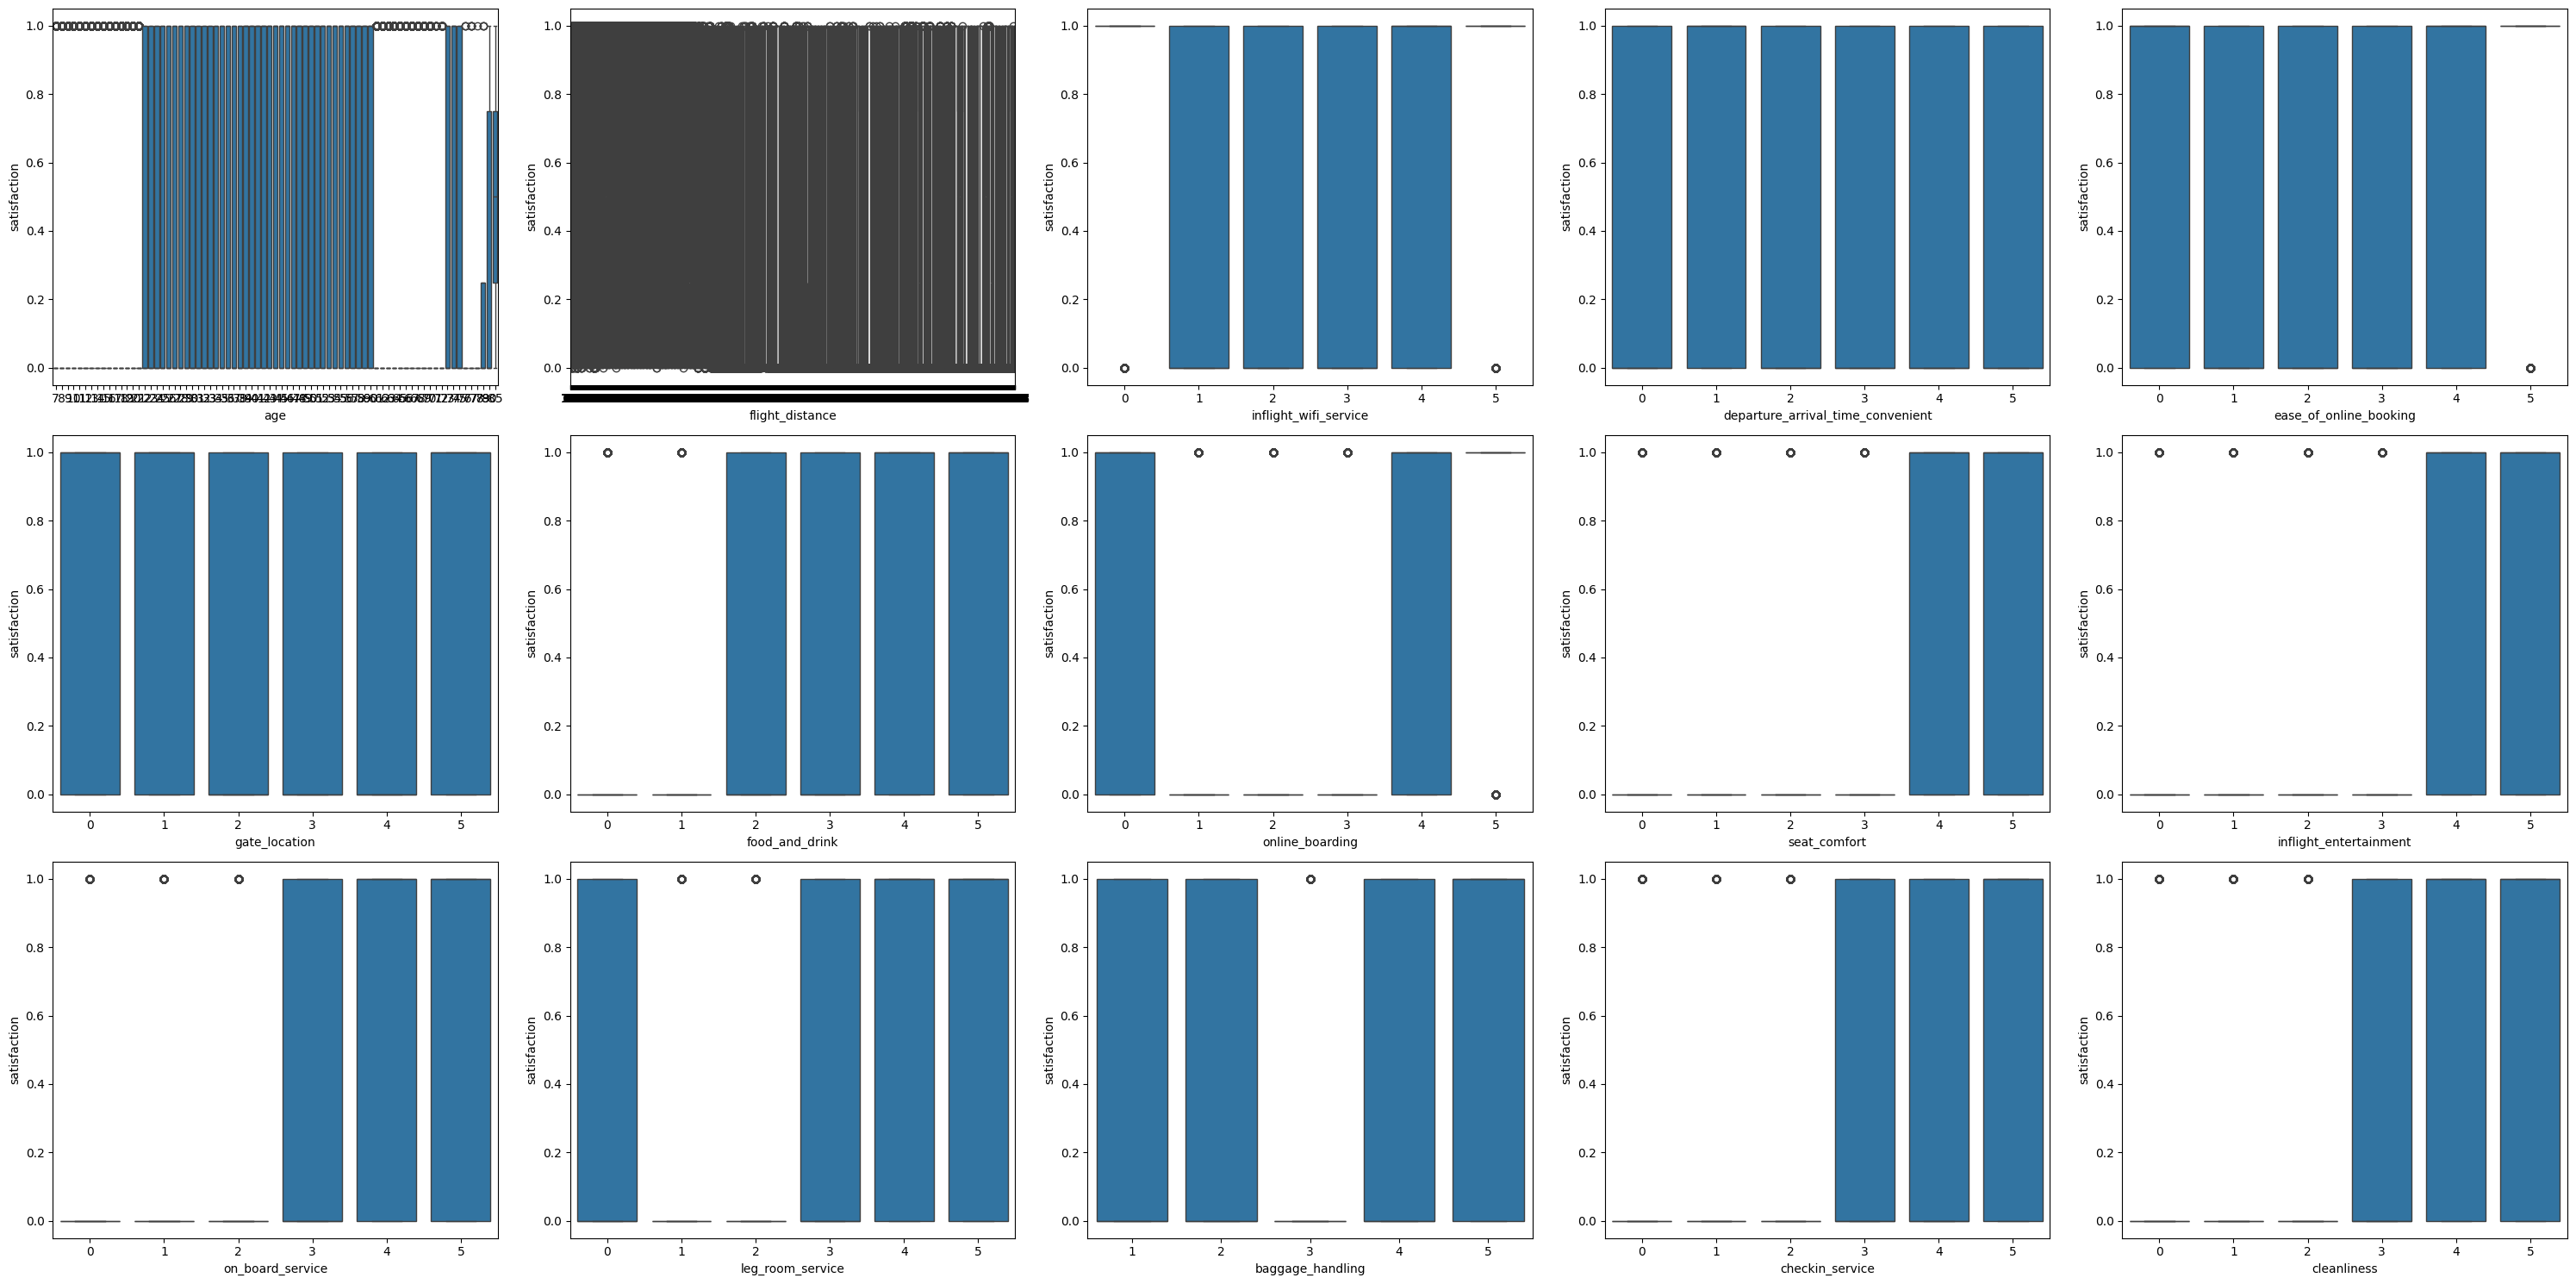

In [259]:
# Gráfico Boxplot para verificação de outliers

aux2 = pd.concat([num_attributes.drop(['satisfaction'], axis=1), df3['satisfaction']], axis=1)

plt.figure(figsize=(30, 15))
plt.subplot(3, 5, 1)
sns.boxplot(x='age', y='satisfaction', data=aux2)

plt.subplot(3, 5, 2)
sns.boxplot(x='flight_distance', y='satisfaction', data=aux2)

plt.subplot(3, 5, 3)
sns.boxplot(x='inflight_wifi_service', y='satisfaction', data=aux2)

plt.subplot(3, 5, 4)
sns.boxplot(x='departure_arrival_time_convenient', y='satisfaction', data=aux2)

plt.subplot(3, 5, 5)
sns.boxplot(x='ease_of_online_booking', y='satisfaction', data=aux2)

plt.subplot(3, 5, 6)
sns.boxplot(x='gate_location', y='satisfaction', data=aux2)

plt.subplot(3, 5, 7)
sns.boxplot(x='food_and_drink', y='satisfaction', data=aux2)

plt.subplot(3, 5, 8)
sns.boxplot(x='online_boarding', y='satisfaction', data=aux2)

plt.subplot(3, 5, 9)
sns.boxplot(x='seat_comfort', y='satisfaction', data=aux2)

plt.subplot(3, 5, 10)
sns.boxplot(x='inflight_entertainment', y='satisfaction', data=aux2)

plt.subplot(3, 5, 11)
sns.boxplot(x='on_board_service', y='satisfaction', data=aux2)

plt.subplot(3, 5, 12)
sns.boxplot(x='leg_room_service', y='satisfaction', data=aux2)

plt.subplot(3, 5, 13)
sns.boxplot(x='baggage_handling', y='satisfaction', data=aux2)

plt.subplot(3, 5, 14)
sns.boxplot(x='checkin_service', y='satisfaction', data=aux2)

plt.subplot(3, 5, 15)
sns.boxplot(x='cleanliness', y='satisfaction', data=aux2)

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

<Axes: xlabel='arrival_delay_in_minutes', ylabel='satisfaction'>

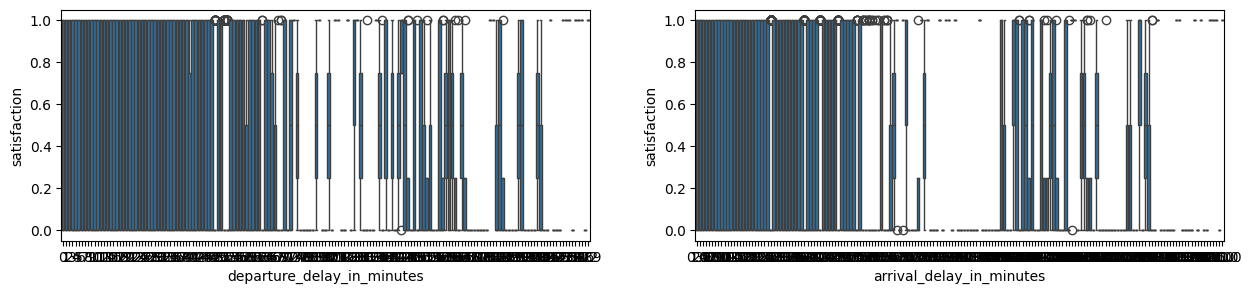

In [260]:
# Gráfico Boxplot para verificação de outliers

aux2 = pd.concat([num_attributes.drop(['satisfaction'], axis=1), df3['satisfaction']], axis=1)

plt.figure(figsize=(15, 3))
plt.subplot(1, 2, 1)
sns.boxplot(x='departure_delay_in_minutes', y='satisfaction', data=aux2)

plt.subplot(1, 2, 2)
sns.boxplot(x='arrival_delay_in_minutes', y='satisfaction', data=aux2)

## 4.5 Transformação

### 4.5.1 Transformação de variáveis categóricas em variáveis numéricas.

In [261]:
# Verificar tabela de variáveis categóricas
df3.head(5).select_dtypes(include=['str','bool'])

,gender,customer_type,type_of_travel,class
0,Female,Loyal Customer,Personal Travel,Eco
1,Male,Loyal Customer,Business travel,Business
2,Female,Loyal Customer,Personal Travel,Eco
3,Male,Loyal Customer,Personal Travel,Eco
4,Female,disloyal Customer,Business travel,Eco


In [262]:
# ============================================================
# ENCODING DAS VARIÁVEIS CATEGÓRICAS
# Regra de ouro: aprender (fit) SÓ no treino; no validação/teste só aplicar (transform)
# ============================================================

# --- 1) Definição das colunas por tipo de encoder -----------
one_hot_cols = ['gender', 'customer_type', 'type_of_travel']  # categorias SEM ordem natural
ordinal_cols = ['class']                                       # categoria COM ordem (Eco < Eco Plus < Business)

# --- 2) Criação dos encoders (ainda não aprenderam nada) ----
ohe = pp.OneHotEncoder(
   sparse_output=False,     # devolve array comum (numpy) em vez de matriz esparsa
   handle_unknown='ignore', # se aparecer categoria nova no val/teste, preenche com 0 em vez de dar erro
   drop='if_binary'         # em colunas com 2 categorias, gera só 1 coluna (evita redundância)
)

oc = pp.OrdinalEncoder(
   categories=[['Eco', 'Eco Plus', 'Business']],  # ordem explícita: Eco=0, Eco Plus=1, Business=2
   dtype=int                                      # saída em inteiro (senão viria float)
)

## 4.5 Encoder

In [263]:
# --- 3) Cópias para não alterar os DataFrames originais -----
# Evita o SettingWithCopyWarning e deixa a célula mais segura
X_train = X_train.copy()
X_val   = X_val.copy()

# --- 4) Ordinal Encoding (coluna 'class') -------------------
# fit_transform no treino: aprende o mapeamento E aplica
X_train[ordinal_cols] = oc.fit_transform(X_train[ordinal_cols])
# transform na validação: só aplica o mapeamento aprendido no treino (NUNCA fit aqui)
X_val[ordinal_cols]   = oc.transform(X_val[ordinal_cols])

# --- 5) One-Hot Encoding ------------------------------------
# fit: aprende quais categorias existem em cada coluna (usa só o treino)
ohe.fit(X_train[one_hot_cols])

# nomes das novas colunas, ex.: 'gender_Male', 'customer_type_disloyal Customer'
ohe_cols_out = ohe.get_feature_names_out(one_hot_cols)

# transform: converte as categorias em colunas 0/1 e já embrulha num DataFrame
# (index=... mantém o mesmo índice das linhas originais, essencial para o concat funcionar)
X_train_ohe = pd.DataFrame(ohe.transform(X_train[one_hot_cols]), columns=ohe_cols_out, index=X_train.index)
X_val_ohe   = pd.DataFrame(ohe.transform(X_val[one_hot_cols]),   columns=ohe_cols_out, index=X_val.index)

# --- 6) Junção final ----------------------------------------
# Remove as colunas de texto originais e cola as novas colunas 0/1 ao lado (axis=1 = colunas)
X_train = pd.concat([X_train.drop(columns=one_hot_cols), X_train_ohe], axis=1)
X_val   = pd.concat([X_val.drop(columns=one_hot_cols),   X_val_ohe],   axis=1)

# --- 7) Verificações ----------------------------------------
print(X_train.dtypes)                                        # nenhuma coluna deve ficar como texto
print(X_train.columns.tolist() == X_val.columns.tolist())    # True = treino e val têm as mesmas colunas, na mesma ordem
print(X_train.isna().sum().sum(), X_val.isna().sum().sum())  # 0 e 0 = nenhum NaN criado pelo encoding

age                                  float64
flight_distance                      float64
inflight_wifi_service                float64
departure_arrival_time_convenient    float64
ease_of_online_booking               float64
gate_location                        float64
food_and_drink                       float64
online_boarding                      float64
seat_comfort                         float64
inflight_entertainment               float64
on_board_service                     float64
leg_room_service                     float64
baggage_handling                     float64
checkin_service                      float64
cleanliness                          float64
departure_delay_in_minutes           float64
arrival_delay_in_minutes             float64
class                                  int64
gender_Male                          float64
customer_type_disloyal Customer      float64
type_of_travel_Personal Travel       float64
dtype: object
True
0 0


In [264]:
del(df2)

# 5.0. FEATURE SELECTION

In [265]:
df4 = df3.copy()

In [266]:
# SHAP (SHapley Additive exPlanations) é uma técnica de explicação de modelos de aprendizado de máquina que atribui a cada recurso
# a importância de sua contribuição para a previsão do modelo.
# Separar as variáveis explicativas (X) e a variável resposta (y)
X = X_train
y = y_train

#Variáveis já tratadas X_train, X_val, y_train, y_val

# Conferir o resultado
print('Dimensão de X:', X_train.shape)
print('Dimensão de y:',  y_train.shape)

print('\nDistribuição da variável resposta:')
print(y_train.value_counts(normalize=True) * 100)

Dimensão de X: (559708, 21)
Dimensão de y: (559708,)

Distribuição da variável resposta:
satisfaction
0    55.642764
1    44.357236
Name: proportion, dtype: float64


### Modelo SHAP

In [ ]:
## ATENÇÃO : COMENTADO APENAS PARA NÃO ALTERAR A SAÍDA
#
## SHAP (SHapley Additive exPlanations) é uma técnica de explicação de modelos de aprendizado de máquina que atribui a cada recurso 
## a importância de sua contribuição para a previsão do modelo.
## Subamostra estratificada do TREINO (X_val fica intocado):
## 100 mil linhas para ajustar o RF e 30 mil de holdout interno para avaliar e explicar
#X_train_shap, X_val_shap, y_train_shap, y_val_shap = train_test_split(
#    X_train,
#    y_train,
#    train_size=100_000,
#    test_size=30_000,
#    stratify=y_train,
#    random_state=42
#)
## RF mais leve: o objetivo é só gerar o ranking de importância
#modelo_shap = RandomForestClassifier(
#    n_estimators=100,
#    max_depth=12,
#    min_samples_leaf=20,
#    random_state=42,
#    n_jobs=-1
#)
## Treinar o modelo
#modelo_shap.fit(X_train_shap, y_train_shap)
## Avaliação no holdout interno
## Fazer previsões
#y_pred_shap = modelo_shap.predict(X_val_shap)
## Avaliar o modelo
#print(classification_report(y_val_shap, y_pred_shap))
#print('ROC AUC:', roc_auc_score(
#    y_val_shap,
#    modelo_shap.predict_proba(X_val_shap)[:, 1]
#))

              precision    recall  f1-score   support

           0       0.92      0.94      0.93     16693
           1       0.92      0.90      0.91     13307

    accuracy                           0.92     30000
   macro avg       0.92      0.92      0.92     30000
weighted avg       0.92      0.92      0.92     30000

ROC AUC: 0.9567338553608632


### cálculo do SHAP em lotes

In [ ]:
## ATENÇÃO : COMENTADO APENAS PARA NÃO ALTERAR A SAÍDA
#
## Amostra a explicar: holdout interno do treino (não usa a validação)
#X_shap = X_val_shap.sample(
#    n=min(10000, len(X_val_shap)),
#    random_state=42
#)
## Criar o explicador SHAP
#explainer = shap.TreeExplainer(modelo_shap)
## Calcular os valores SHAP em lotes para limitar o pico de memória
#batch_size = 250
#shap_batches = []
## print('Dimensão dos valores SHAP:', shap_satisfaction.shape)
#for start in range(0, len(X_shap), batch_size):
#    batch = X_shap.iloc[start:start + batch_size]
#    sv = explainer.shap_values(batch)
#    # Selecionar a classe de passageiros satisfeitos (1)
#    if isinstance(sv, list):
#        sv = sv[1]
#    elif isinstance(sv, np.ndarray) and sv.ndim == 3:
#        sv = sv[:, :, 1]
#    shap_batches.append(sv)
#    gc.collect()
#shap_satisfaction = np.vstack(shap_batches)
#print('Dimensão dos valores SHAP:', shap_satisfaction.shape)

Dimensão dos valores SHAP: (10000, 21)


### Lista SHAP

In [ ]:
## ATENÇÃO : COMENTADO APENAS PARA NÃO ALTERAR A SAÍDA
#
## Calcular a importância global
#importancia_shap = pd.DataFrame({
#    'Variavel': X_shap.columns,
#    'Importancia_SHAP': np.abs(shap_satisfaction).mean(axis=0)
#})
## Ordenar da maior para a menor importância
#importancia_shap = importancia_shap.sort_values(
#    by='Importancia_SHAP',
#    ascending=False
#)
## Exibir as 20 variáveis mais importantes
#display(importancia_shap)

,Variavel,Importancia_SHAP
7,online_boarding,0.104564
17,class,0.082383
20,type_of_travel_Personal Travel,0.081071
2,inflight_wifi_service,0.074730
9,inflight_entertainment,0.038936
19,customer_type_disloyal Customer,0.032195
8,seat_comfort,0.031245
11,leg_room_service,0.024948
10,on_board_service,0.023059
1,flight_distance,0.020821


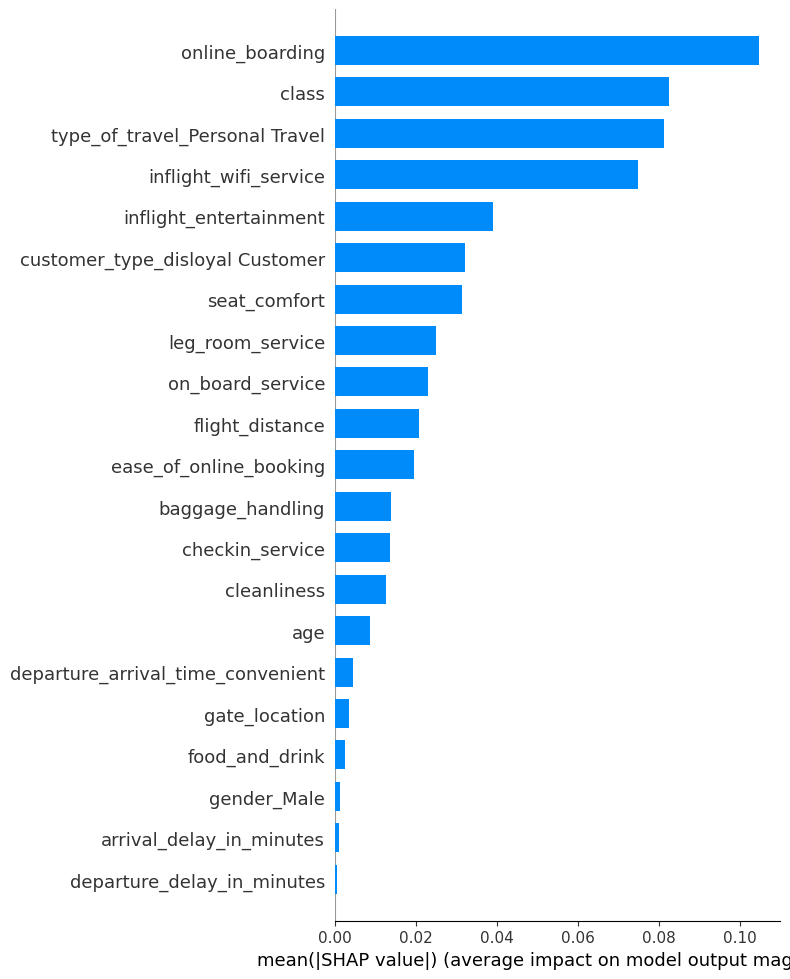

In [ ]:
## ATENÇÃO : COMENTADO APENAS PARA NÃO ALTERAR A SAÍDA
#
## Visualizar os TOP 10 valores SHAP
#shap.summary_plot(
#    shap_satisfaction,
#    X_shap,
#    plot_type='bar',
#    max_display=21
#)

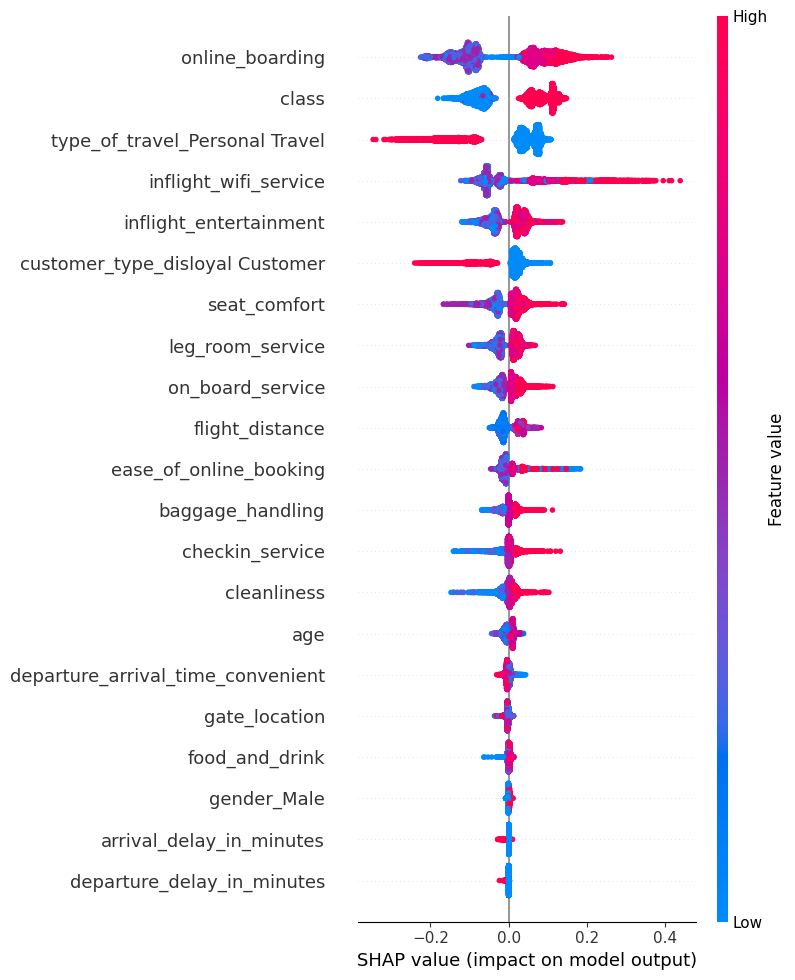

In [ ]:
## ATENÇÃO : COMENTADO APENAS PARA NÃO ALTERAR A SAÍDA
#
#shap.summary_plot(
#    shap_satisfaction,
#    X_shap,
#    max_display=21
#)

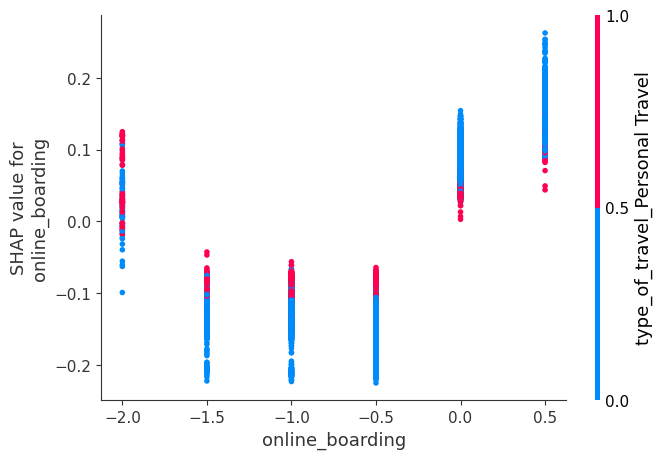

In [ ]:
## ATENÇÃO : COMENTADO APENAS PARA NÃO ALTERAR A SAÍDA
#
## Analisar a relação entre a variável 'online_boarding' e os valores SHAP para a classe de passageiros satisfeitos
#shap.dependence_plot(
#    'online_boarding',
#    shap_satisfaction,
#    X_shap
#)

## 5.1. Filter Method

In [273]:
df5 = df4.copy()

In [274]:
# Remove variáveis com variância abaixo do threshold
selector = VarianceThreshold(threshold=0.01)
X_filtered = selector.fit_transform(num_attributes)

# Verificar variância manualmente
variances = num_attributes.var()
low_var_cols = variances[variances < 0.01].index.tolist()
print("Variáveis com variância quasi-zero:", low_var_cols)

Variáveis com variância quasi-zero: []


## 5.2 Wrapper Method Boruta

In [275]:
df5.sample(5)

,age,flight_distance,inflight_wifi_service,departure_arrival_time_convenient,ease_of_online_booking,gate_location,food_and_drink,online_boarding,seat_comfort,inflight_entertainment,on_board_service,leg_room_service,baggage_handling,checkin_service,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,gender,customer_type,type_of_travel,class,satisfaction
255234,34,1138,3,4,3,3,3,3,3,3,5,4,4,5,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco Plus,0
514630,29,2296,5,5,5,3,3,5,3,3,5,4,5,4,3,0,0.0,Male,disloyal Customer,Business travel,Business,1
138878,56,533,2,5,2,3,2,2,2,2,3,5,4,4,2,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
512435,36,337,1,0,1,5,4,1,3,4,1,1,2,1,4,1,0.0,Female,disloyal Customer,Business travel,Eco,0
474708,21,1357,1,1,1,2,5,1,5,5,1,2,2,1,5,0,0.0,Female,disloyal Customer,Business travel,Eco,0


In [ ]:
# preparacao dados
X = df4.drop( columns='satisfaction' )
y = df4['satisfaction'].apply(lambda x: 1 if x == 'Yes' else 0)
X_boruta = pd.get_dummies( X, prefix_sep='__SEP__', dtype=int)
# algoritmo
rf = en.RandomForestClassifier(n_jobs=-1, max_depth=5, random_state=42)
# boruta
boruta = BorutaPy( rf, 
                   n_estimators='auto',
                   verbose=2,
                   random_state=42
).fit( X_boruta.values, y.values )

# resultados
confirmed_boruta = X_boruta.columns[boruta.support_].tolist()
tentative_boruta = X_boruta.columns[boruta.support_weak_].tolist()
rejected_boruta = X_boruta.columns[~boruta.support_ & ~boruta.support_weak_].tolist()
confirmed_boruta = sorted( set( to_original( c ) for c in confirmed_boruta ) )
tentative_boruta = sorted( set( to_original( c ) for c in tentative_boruta ) )
rejected_boruta  = sorted( set( to_original( c ) for c in rejected_boruta ) )

# Categórica só é "rejeitada" se TODAS as suas dummies foram rejeitadas.
# Se ao menos uma dummy foi confirmada/tentativa, removemos a original da lista de rejeitadas.
rejected_boruta = [ c for c in rejected_boruta
                      if c not in confirmed_boruta and c not in tentative_boruta ]
print( f'Variaveis confirmadas (originais): {confirmed_boruta}' )
print( f'Variaveis tentativas (originais):  {tentative_boruta}' )
print( f'Variaveis rejeitadas (originais):  {rejected_boruta}' )

# FINALIZAR QUANDO FINALIZAR A EDA
# --- 1) Filter Method
rejected_columns = ( low_variance 
                    + low_univariate_discriminative 
                    + low_correlation 
                    + low_bivariate_discriminative 
                    + low_bivariate_cat_discriminative 
                    + auto_corr
                    + rejected_boruta )

Iteration: 	1 / 100
Confirmed: 	0
Tentative: 	26
Rejected: 	0
Iteration: 	2 / 100
Confirmed: 	0
Tentative: 	26
Rejected: 	0
Iteration: 	3 / 100
Confirmed: 	0
Tentative: 	26
Rejected: 	0
Iteration: 	4 / 100
Confirmed: 	0
Tentative: 	26
Rejected: 	0
Iteration: 	5 / 100
Confirmed: 	0
Tentative: 	26
Rejected: 	0
Iteration: 	6 / 100
Confirmed: 	0
Tentative: 	26
Rejected: 	0
Iteration: 	7 / 100
Confirmed: 	0
Tentative: 	26
Rejected: 	0
Iteration: 	8 / 100
Confirmed: 	0
Tentative: 	0
Rejected: 	26


BorutaPy finished running.

Iteration: 	9 / 100
Confirmed: 	0
Tentative: 	0
Rejected: 	26
Variaveis confirmadas (originais): []
Variaveis tentativas (originais):  []
Variaveis rejeitadas (originais):  ['age', 'arrival_delay_in_minutes', 'baggage_handling', 'checkin_service', 'class', 'cleanliness', 'customer_type', 'departure_arrival_time_convenient', 'departure_delay_in_minutes', 'ease_of_online_booking', 'flight_distance', 'food_and_drink', 'gate_location', 'gender', 'inflight_entertainment', 'i

In [277]:
#rejected_columns = sorted( set(rejected_columns)) #ajuste pegando apenas as variáveis rejeitadas pelo Boruta
rejected_boruta = [] 
rejected_shap = ['departure_arrival_time_convenient', 
                 'gate_location', 
                 'food_and_drink',
                 'age',
                 'gender_Male',
                 'arrival_delay_in_minutes',
                 'departure_delay_in_minutes']

rejected_columns = sorted( set(rejected_boruta + rejected_shap))

print( f"\nTotal de variáveis a serem removidas: {len(rejected_columns)}")
print( f"Variáveis a serem removidas: {rejected_columns}")


Total de variáveis a serem removidas: 7
Variáveis a serem removidas: ['age', 'arrival_delay_in_minutes', 'departure_arrival_time_convenient', 'departure_delay_in_minutes', 'food_and_drink', 'gate_location', 'gender_Male']


## 5.3 Wrapper Method RFECV

## 5.4. Final Features Selection

In [ ]:
X_train = X_train.drop(columns=rejected_columns)
X_val   = X_val.drop(columns=rejected_columns)

print(X_train.shape, X_val.shape)
print(X_train.columns.tolist() == X_val.columns.tolist())

(559708, 14) (139927, 14)
True


# 6.0. Machine Learning Modeling

## 6.1. Baseline Model

In [279]:
#Modelo de predição meramente aleatório, para servir de baseline para comparação com os modelos que serão criados posteriormente.
yhat_baseline_train = np.random.choice([0.1, 0.9], size = len(y_train), p=[0.5, 0.5])
yhat_baseline_val = np.random.choice([0.1, 0.9], size = len(y_val), p=[0.5, 0.5])

baseline_train = ml_metrics('Baseline Train', y_train, yhat_baseline_train )
baseline_val = ml_metrics('Baseline Val', y_val, yhat_baseline_val)

baseline = pd.concat( [baseline_train, baseline_val] )
baseline

,Model,Accuracy,F1 Score,precision,Recall,AUC,ROC AUC
0,Baseline Train,0.500059,0.470344,0.443668,0.500433,0.500097,0.500097
0,Baseline Val,0.501240,0.471920,0.444914,0.502417,0.501359,0.501359


## 6.2 Regressão Logística

In [280]:
# definição
lr_model = LogisticRegression(random_state=42, max_iter=1000)

# treinamento
lr_model.fit(X_train, y_train)

# previsão
yhat_lr_train = lr_model.predict_proba(X_train)[:, 1]
yhat_lr_val = lr_model.predict_proba(X_val)[:, 1]

# desempenho
lr_train = ml_metrics('Logistic Regression Train', y_train, yhat_lr_train)
lr_val = ml_metrics('Logistic Regression Validation', y_val, yhat_lr_val)

lr = pd.concat([lr_train, lr_val])
lr

,Model,Accuracy,F1 Score,precision,Recall,AUC,ROC AUC
0,Logistic Regression Train,0.877515,0.859770,0.873452,0.846510,0.874371,0.920635
0,Logistic Regression Validation,0.877129,0.859273,0.873305,0.845685,0.873940,0.919212


## 6.3. Random Forest

In [281]:
# definition
rf_model = en.RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    max_depth=12,
    random_state=42,
    n_jobs=-1
    )

# treinamento
rf_model.fit(X_train, y_train)

# previsão
yhat_rf_train = rf_model.predict_proba(X_train)[:, 1]
yhat_rf_val = rf_model.predict_proba(X_val)[:, 1]

# performance
rf_train = ml_metrics('Random Forest Train', y_train, yhat_rf_train)
rf_val = ml_metrics('Random Forest Validation', y_val, yhat_rf_val)

rf = pd.concat([rf_train, rf_val])
rf

,Model,Accuracy,F1 Score,precision,Recall,AUC,ROC AUC
0,Random Forest Train,0.921952,0.912286,0.909569,0.91502,0.921249,0.959551
0,Random Forest Validation,0.918222,0.907990,0.906307,0.90968,0.917355,0.954362


## 6.4. LGBM Classifier

In [282]:
# definition
lgbm_model = lgb.LGBMClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
# training
lgbm_model.fit(X_train, y_train)

# previsão
yhat_lgbm_train = lgbm_model.predict_proba(X_train)[:, 1]
yhat_lgbm_val = lgbm_model.predict_proba(X_val)[:, 1]

# performance
lgbm_train = ml_metrics('LightGBM Train', y_train, yhat_lgbm_train)
lgbm_val = ml_metrics('LightGBM Validation', y_val, yhat_lgbm_val)

lgbm = pd.concat([lgbm_train, lgbm_val])
lgbm

,Model,Accuracy,F1 Score,precision,Recall,AUC,ROC AUC
0,LightGBM Train,0.923515,0.913537,0.916178,0.910912,0.922237,0.958096
0,LightGBM Validation,0.921352,0.910966,0.914897,0.907070,0.919904,0.955761


## 6.5. XGBoost

In [283]:
# definition
ratio = float( np.sum( y_train==0 ) ) / np.sum( y_train == 1 )
xgb_model = XGBClassifier(
    n_estimators = 100,
    scale_pos_weight = ratio,
    random_state=42,
    n_jobs=-1    
)

# training
xgb_model.fit(X_train, y_train)

# prediction
yhat_xgb_train = xgb_model.predict_proba(X_train)[:, 1]
yhat_xgb_val = xgb_model.predict_proba(X_val)[:, 1]

# performance
xgb_train = ml_metrics('XGBoost Train', y_train, yhat_xgb_train)
xgb_val = ml_metrics('XGBoost Validation', y_val, yhat_xgb_val)

xgb = pd.concat([xgb_train, xgb_val])
xgb

,Model,Accuracy,F1 Score,precision,Recall,AUC,ROC AUC
0,XGBoost Train,0.925897,0.916232,0.918856,0.913623,0.924652,0.962482
0,XGBoost Validation,0.921938,0.911650,0.915374,0.907956,0.920520,0.956250


In [284]:
print( "===== Training Metrics ====")
display( pd.concat( [baseline_train, lr_train, rf_train, lgbm_train, xgb_train] ).reset_index(drop=True))

print( "===== Validation Metrics ====")
display( pd.concat( [baseline_val, lr_val, rf_val, lgbm_val, xgb_val] ).reset_index(drop=True))

===== Training Metrics ====


,Model,Accuracy,F1 Score,precision,Recall,AUC,ROC AUC
0,Baseline Train,0.500059,0.470344,0.443668,0.500433,0.500097,0.500097
1,Logistic Regression Train,0.877515,0.859770,0.873452,0.846510,0.874371,0.920635
2,Random Forest Train,0.921952,0.912286,0.909569,0.915020,0.921249,0.959551
3,LightGBM Train,0.923515,0.913537,0.916178,0.910912,0.922237,0.958096
4,XGBoost Train,0.925897,0.916232,0.918856,0.913623,0.924652,0.962482


===== Validation Metrics ====


,Model,Accuracy,F1 Score,precision,Recall,AUC,ROC AUC
0,Baseline Val,0.501240,0.471920,0.444914,0.502417,0.501359,0.501359
1,Logistic Regression Validation,0.877129,0.859273,0.873305,0.845685,0.873940,0.919212
2,Random Forest Validation,0.918222,0.907990,0.906307,0.909680,0.917355,0.954362
3,LightGBM Validation,0.921352,0.910966,0.914897,0.907070,0.919904,0.955761
4,XGBoost Validation,0.921938,0.911650,0.915374,0.907956,0.920520,0.956250


## 6.6. CV para comparar modelos (antes do fine tuning)

In [ ]:
# Cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'roc_auc': 'roc_auc',
    'neg_log_loss': 'neg_log_loss',
    'neg_brier': 'neg_brier_score',
    'f1': 'f1',
}

modelos = {
    'LogReg': lr_model,
    'RandomForest': rf_model,
    'LightGBM': lgbm_model,
    'XGBoost': xgb_model,
}

resultados = []
for nome, modelo in modelos.items():
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    resultados.append({
        'Model': nome,
        'ROC AUC': f"{r['test_roc_auc'].mean():.4f} ± {r['test_roc_auc'].std():.4f}",
        'Log Loss': f"{-r['test_neg_log_loss'].mean():.4f} ± {r['test_neg_log_loss'].std():.4f}",
        'Brier': f"{-r['test_neg_brier'].mean():.4f} ± {r['test_neg_brier'].std():.4f}",
        'F1': f"{r['test_f1'].mean():.4f} ± {r['test_f1'].std():.4f}",
    })

display(pd.DataFrame(resultados))


,Model,ROC AUC,Log Loss,Brier,F1
0,LogReg,0.9206 ± 0.0008,0.3464 ± 0.0019,0.0982 ± 0.0007,0.8597 ± 0.0010
1,RandomForest,0.9554 ± 0.0006,0.2423 ± 0.0021,0.0655 ± 0.0007,0.9093 ± 0.0011
2,LightGBM,0.9570 ± 0.0005,0.2346 ± 0.0019,0.0630 ± 0.0006,0.9130 ± 0.0007
3,XGBoost,0.9572 ± 0.0006,0.2339 ± 0.0018,0.0626 ± 0.0006,0.9137 ± 0.0008


## 6.7 CV para o fine tuning - Melhores hiperparâmetros

In [113]:
# Cross-validation para fine tuning
param_dist = {
    'n_estimators': [200, 400, 600],
    'learning_rate': [0.03, 0.05, 0.1],
    'num_leaves': [31, 63, 127],
    'min_child_samples': [20, 50, 100],
    'subsample': [0.7, 0.85, 1.0],
    'colsample_bytree': [0.7, 0.85, 1.0],
}

busca = RandomizedSearchCV(
    estimator=XGBClassifier(random_state=42, n_jobs=-1, verbose=-1),
    param_distributions=param_dist,
    n_iter=20,
    scoring='neg_log_loss',   # ou 'roc_auc'
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=1,
    verbose=1,
)

busca.fit(X_train, y_train)
print(busca.best_params_)
print(busca.best_score_)


Fitting 3 folds for each of 20 candidates, totalling 60 fits


/home/alvaro/.pyenv/versions/3.12.12/envs/airline/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [16:33:54] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "min_child_samples", "num_leaves", "verbose" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/home/alvaro/.pyenv/versions/3.12.12/envs/airline/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [16:33:59] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "min_child_samples", "num_leaves", "verbose" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/home/alvaro/.pyenv/versions/3.12.12/envs/airline/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [16:34:04] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "min_child_samples", "num_leaves", "verbose" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/home/alvaro/.pyenv/versions/3.12.12/envs/airline/lib/python3.12/site-packages/xgboost/training.py:200:

{'subsample': 0.85, 'num_leaves': 127, 'n_estimators': 600, 'min_child_samples': 50, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
-0.23143427073955536


## 6.8 Busca Bayesiana com Optuna (TPE)

Alternativa ao Random Search acima. O Optuna usa o algoritmo **TPE (Tree-structured Parzen Estimator)**, que aprende com as tentativas anteriores e passa a sortear hiperparâmetros em regiões mais promissoras, em vez de sortear às cegas.

- **Modelo:** XGBoost (melhor modelo na CV da seção 6.6).
- **Espaço de busca:** contínuo, com `learning_rate`, `reg_lambda` e `reg_alpha` em escala logarítmica.
- **Avaliação:** `StratifiedKFold` de 5 folds, os mesmos da seção 6.6, somente no treino.
- **Validação:** usada apenas no final, para avaliar o modelo já escolhido.

In [ ]:
import optuna
from sklearn.model_selection import cross_val_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

# Métrica otimizada na busca ('roc_auc', 'recall', 'f1', 'neg_log_loss'...)
METRICA_OPTUNA = 'roc_auc'

# Mesmos folds da seção 6.6, para os resultados serem comparáveis
cv_optuna = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Desbalanceamento das classes (mesma lógica do XGBoost da seção 6.5)
ratio_optuna = float(np.sum(y_train == 0)) / np.sum(y_train == 1)

def objective(trial):
    """Cada chamada sorteia uma combinação de hiperparâmetros e devolve o score médio da CV."""
    params = {
        'n_estimators':     trial.suggest_int('n_estimators', 100, 2000),
        'learning_rate':    trial.suggest_float('learning_rate', 0.005, 0.3, log=True),
        'max_depth':        trial.suggest_int('max_depth', 3, 10),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 20),
        'subsample':        trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_lambda':       trial.suggest_float('reg_lambda', 0.01, 10.0, log=True),
        'reg_alpha':        trial.suggest_float('reg_alpha', 0.001, 1.0, log=True),
        # Parâmetros fixos
        'scale_pos_weight': ratio_optuna,
        'eval_metric':      'auc',
        'random_state':     42,
        'n_jobs':           -1,
    }

    scores = cross_val_score(
        XGBClassifier(**params), X_train, y_train,
        scoring=METRICA_OPTUNA, cv=cv_optuna,
        n_jobs=1,  # o paralelismo já é feito pelo XGBoost (n_jobs=-1)
    )
    return scores.mean()

In [ ]:
# Estudo Optuna: maximiza a métrica escolhida com o sampler TPE (seed fixa = reprodutível)
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42),
)

study.optimize(
    objective,
    n_trials=50,             # número de combinações avaliadas
    timeout=3600,             # limite de segurança: 1 hora
    show_progress_bar=True,
)

print(f'Melhor {METRICA_OPTUNA} (CV): {study.best_value:.4f}')
print(f'Melhores parâmetros: {study.best_params}')

Best trial: 6. Best value: 0.957741: 100%|██████████| 10/10 [05:17<00:00, 31.74s/it, 317.45/3600 seconds]

Melhor roc_auc (CV): 0.9577
Melhores parâmetros: {'n_estimators': 1139, 'learning_rate': 0.010657839740514352, 'max_depth': 10, 'min_child_weight': 16, 'subsample': 0.9697494707820946, 'colsample_bytree': 0.9474136752138245, 'reg_lambda': 0.6218704727769077, 'reg_alpha': 0.5829384542994738}


### Modelo final com os parâmetros do Optuna

O modelo é reajustado em todo o `X_train` com os melhores hiperparâmetros e só então avaliado na validação.

In [ ]:
# Reajuste no treino completo com os melhores parâmetros encontrados
xgb_optuna = XGBClassifier(
    **study.best_params,
    scale_pos_weight=ratio_optuna,
    eval_metric='auc',
    random_state=42,
    n_jobs=-1,
)
xgb_optuna.fit(X_train, y_train)

# Probabilidades de satisfação (classe 1)
yhat_optuna_train = xgb_optuna.predict_proba(X_train)[:, 1]
yhat_optuna_val   = xgb_optuna.predict_proba(X_val)[:, 1]

optuna_train = ml_metrics('XGBoost Optuna Train', y_train, yhat_optuna_train)
optuna_val   = ml_metrics('XGBoost Optuna Validation', y_val, yhat_optuna_val)

display(pd.concat([optuna_train, optuna_val]).reset_index(drop=True))

# Comparação na validação com os modelos da seção 6
# (o Random Search, final_val, só é calculado mais abaixo, em "Métricas de treino e validação")
display(
    pd.concat([baseline_val, lr_val, rf_val, lgbm_val, xgb_val, optuna_val])
      .reset_index(drop=True)
      .sort_values('ROC AUC', ascending=False)
)

,Model,Accuracy,F1 Score,precision,Recall,AUC,ROC AUC
0,XGBoost Optuna Train,0.927941,0.918412,0.922522,0.914340,0.926562,0.966036
1,XGBoost Optuna Validation,0.922653,0.912314,0.917570,0.907118,0.921077,0.956935


,Model,Accuracy,F1 Score,precision,Recall,AUC,ROC AUC
5,XGBoost Optuna Validation,0.922653,0.912314,0.917570,0.907118,0.921077,0.956935
4,XGBoost Validation,0.921938,0.911650,0.915374,0.907956,0.920520,0.956250
3,LightGBM Validation,0.921352,0.910966,0.914897,0.907070,0.919904,0.955761
2,Random Forest Validation,0.918222,0.907990,0.906307,0.909680,0.917355,0.954362
1,Logistic Regression Validation,0.877129,0.859273,0.873305,0.845685,0.873940,0.919212
0,Baseline Val,0.498589,0.469470,0.442340,0.500145,0.498746,0.498746


### Diagnóstico da busca

Gráficos interativos para entender como o Optuna explorou o espaço de hiperparâmetros.

In [ ]:
import optuna.visualization as vis

# Evolução da métrica ao longo dos trials
vis.plot_optimization_history(study).show()

# Quais hiperparâmetros mais influenciaram o resultado
vis.plot_param_importances(study).show()

# Relação individual entre alguns hiperparâmetros e a métrica
vis.plot_slice(study, params=['learning_rate', 'max_depth']).show()

# Interação entre 2 hiperparâmetros
vis.plot_contour(study, params=['learning_rate', 'max_depth']).show()

# Todos os hiperparâmetros ao mesmo tempo
vis.plot_parallel_coordinate(study).show()

### Resultado final do fine tuning
- O modelo mais complexo que roda o Optuna não apresentou melhoria significativas quando comparado com o modelo de Random Search Cross Validation. Optou-se utilizar os valores apresentados no Random Search Cross Validation pela velocidade de processamento.

# 7.0 Modelo final e probabilidades

In [119]:
# O melhor modelo da busca já foi reajustado em todo o X_train (refit=True)
modelo_final = busca.best_estimator_
print('Hiperparâmetros escolhidos:', busca.best_params_)

# Probabilidades de satisfação (classe 1)
yhat_final_train = modelo_final.predict_proba(X_train)[:, 1]
yhat_final_val   = modelo_final.predict_proba(X_val)[:, 1]   # primeira e única vez que a validação é usada para avaliar


Hiperparâmetros escolhidos: {'subsample': 0.85, 'num_leaves': 127, 'n_estimators': 600, 'min_child_samples': 50, 'learning_rate': 0.05, 'colsample_bytree': 0.7}


## 7.1 Métricas de treino e validação

In [120]:
final_train = ml_metrics('Modelo Final Train', y_train, yhat_final_train)
final_val   = ml_metrics('Modelo Final Validation', y_val, yhat_final_val)

resultado_final = pd.concat([final_train, final_val]).reset_index(drop=True)
display(resultado_final)

# Indicador de overfitting
gap_auc = final_train['ROC AUC'].iloc[0] - final_val['ROC AUC'].iloc[0]
print(f'Diferença de AUC (treino - validação): {gap_auc:.4f}')


,Model,Accuracy,F1 Score,precision,Recall,AUC,ROC AUC
0,Modelo Final Train,0.926337,0.916040,0.926363,0.905946,0.924269,0.962373
1,Modelo Final Validation,0.922938,0.912061,0.923486,0.900915,0.920705,0.956746


Diferença de AUC (treino - validação): 0.0056


## 7.2 Comparação entre os modelos

In [121]:
# Use ml_metrics para os modelos da seção 6 também, ajustados em X_train_sel
comparacao = pd.concat([
    baseline_val, lr_val, rf_val, lgbm_val, xgb_val, final_val
]).reset_index(drop=True)

display(comparacao.sort_values('ROC AUC', ascending=False))


,Model,Accuracy,F1 Score,precision,Recall,AUC,ROC AUC
5,Modelo Final Validation,0.922938,0.912061,0.923486,0.900915,0.920705,0.956746
4,XGBoost Validation,0.921938,0.911650,0.915374,0.907956,0.920520,0.956250
3,LightGBM Validation,0.921352,0.910966,0.914897,0.907070,0.919904,0.955761
2,Random Forest Validation,0.918222,0.907990,0.906307,0.909680,0.917355,0.954362
1,Logistic Regression Validation,0.877129,0.859273,0.873305,0.845685,0.873940,0.919212
0,Baseline Val,0.498589,0.469470,0.442340,0.500145,0.498746,0.498746


## 7.3 Curvas ROC, precisão/recall e calibração



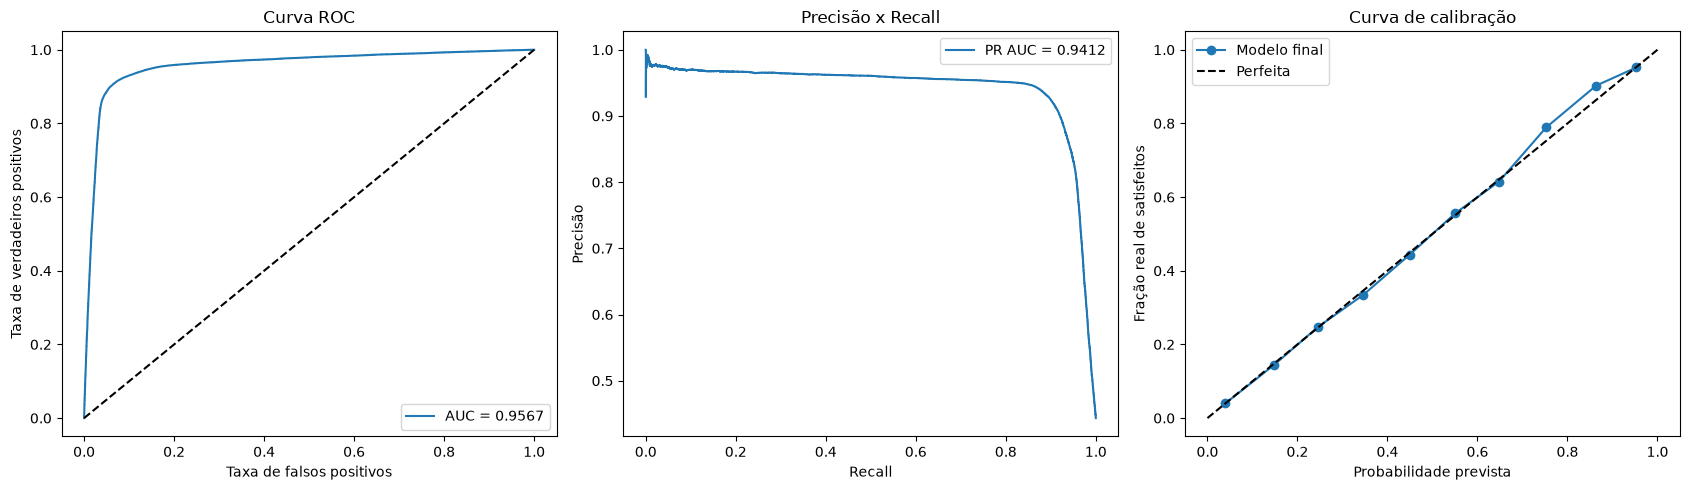

In [122]:
# Gráficos
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# ROC
fpr, tpr, _ = mt.roc_curve(y_val, yhat_final_val)
axes[0].plot(fpr, tpr, label=f"AUC = {mt.roc_auc_score(y_val, yhat_final_val):.4f}")
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_xlabel('Taxa de falsos positivos'); axes[0].set_ylabel('Taxa de verdadeiros positivos')
axes[0].set_title('Curva ROC'); axes[0].legend()

# Precisão x Recall
prec, rec, _ = mt.precision_recall_curve(y_val, yhat_final_val)
axes[1].plot(rec, prec, label=f"PR AUC = {mt.average_precision_score(y_val, yhat_final_val):.4f}")
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precisão')
axes[1].set_title('Precisão x Recall'); axes[1].legend()

# Calibração
frac_pos, media_prob = calibration_curve(y_val, yhat_final_val, n_bins=10)
axes[2].plot(media_prob, frac_pos, marker='o', label='Modelo final')
axes[2].plot([0, 1], [0, 1], 'k--', label='Perfeita')
axes[2].set_xlabel('Probabilidade prevista'); axes[2].set_ylabel('Fração real de satisfeitos')
axes[2].set_title('Curva de calibração'); axes[2].legend()

plt.tight_layout()
plt.show()


# 8.0 Avaliação Real do Algoritmo Treinado

## 8.1 Preparação dos dados de teste

## 8.2. Treinamento XGBoost Best Hiperparameter

# 10.0. Test Dataset